# TP 2 - Predicción de lluvia en Australia

## 1. Análisis descriptivo

El objetivo es estudiar las observaciones meteorológicas y preparar el problema de clasificación de `RainTomorrow`. 

En este primer avance revisamos el archivo entregado, describimos sus variables y hacemos un diagnóstico de los faltantes.

In [1]:
# Importo las librerías que uso en el notebook.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, balanced_accuracy_score, matthews_corrcoef, average_precision_score, roc_curve, auc

In [2]:
# Cargo el CSV entregado y convierto Date a fecha para resumir el período.
DATA_PATH = Path("weatherAUS_2026C2.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("..") / "weatherAUS_2026C2.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"No se encontró el archivo: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")


In [3]:
# Muestro las primeras filas para ver la estructura del archivo.
display(df.head())

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


### Variables del archivo

El CSV no incluye un diccionario de datos. Esta primera descripción toma los nombres de las columnas y los valores observados en el archivo.

| Variable | Qué representa |
| --- | --- |
| `Unnamed: 0` | Índice que quedó guardado junto con el CSV; no describe el clima. |
| `Date` | Fecha asociada a la observación. |
| `Location` | Ciudad o ubicación de la observación. |
| `MinTemp`, `MaxTemp` | Temperatura mínima y máxima. |
| `Rainfall` | Lluvia observada en la fecha de la fila. |
| `Evaporation` | Evaporación observada. |
| `Sunshine` | Horas de sol registradas. |
| `WindGustDir`, `WindGustSpeed` | Dirección y velocidad de la ráfaga máxima. |
| `WindDir9am`, `WindDir3pm` | Dirección del viento cerca de las 9 y las 15 h. |
| `WindSpeed9am`, `WindSpeed3pm` | Velocidad del viento cerca de las 9 y las 15 h. |
| `Humidity9am`, `Humidity3pm` | Humedad observada cerca de las 9 y las 15 h. |
| `Pressure9am`, `Pressure3pm` | Presión observada cerca de las 9 y las 15 h. |
| `Cloud9am`, `Cloud3pm` | Cobertura de nubes cerca de las 9 y las 15 h. |
| `Temp9am`, `Temp3pm` | Temperatura cerca de las 9 y las 15 h. |
| `RainToday` | Indicador categórico de lluvia en la fecha de la fila. |
| `RainTomorrow` | Indicador de lluvia al día siguiente; es la variable objetivo. |
| `RainfallTomorrow` | Cantidad de lluvia del día siguiente. Se excluye de los predictores porque corresponde a información futura. |



In [4]:
# Resumo tipos, valores distintos y rangos numéricos para completar la descripción.
estructura = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores distintos": df.nunique(dropna=True),
    "faltantes": df.isna().sum(),
})
display(estructura)

columnas_numericas = df.select_dtypes(include="number").columns.tolist()
columnas_para_describir = [
    columna for columna in columnas_numericas if columna != "Unnamed: 0"
]
columnas_predictoras_numericas = [
    columna for columna in columnas_para_describir if columna != "RainfallTomorrow"
]
variables_numericas = df[columnas_para_describir]
rangos = variables_numericas.describe().T[["min", "50%", "max"]]
rangos = rangos.rename(columns={"min": "mínimo observado", "50%": "mediana", "max": "máximo observado"})
display(rangos.round(2))

,tipo,valores distintos,faltantes
Unnamed: 0,int64,145412,0
Date,datetime64[us],3435,0
Location,str,49,0
MinTemp,float64,395,1484
MaxTemp,float64,506,1253
Rainfall,float64,681,3260
Evaporation,float64,358,62754
Sunshine,float64,145,69796
WindGustDir,str,16,10316
WindGustSpeed,float64,120,10253


,mínimo observado,mediana,máximo observado
MinTemp,-9.7,12.0,34.1
MaxTemp,-5.1,22.6,49.1
Rainfall,0.0,0.0,371.0
Evaporation,0.0,4.8,145.0
Sunshine,0.0,8.4,14.5
WindGustSpeed,6.0,38.0,135.0
WindSpeed9am,0.0,13.0,130.0
WindSpeed3pm,0.0,18.0,86.0
Humidity9am,0.0,69.9,100.0
Humidity3pm,0.0,52.0,100.0


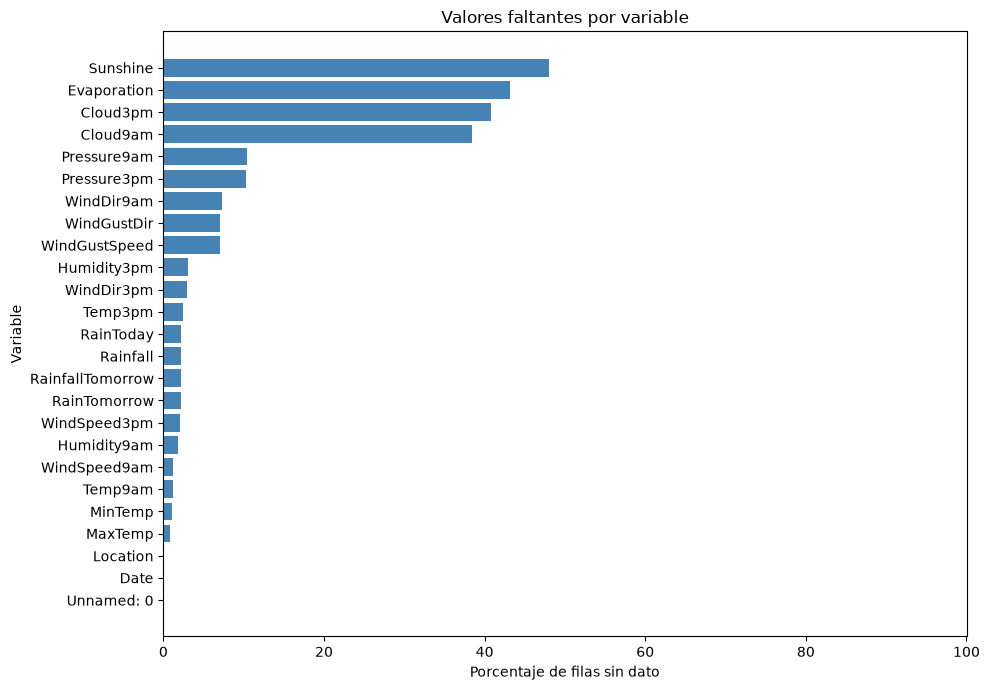

In [5]:
# Calculo y grafico el porcentaje de faltantes para comparar variables en la misma escala.
fig, ax = plt.subplots(figsize=(10, 7))
faltantes = pd.DataFrame({"porcentaje": df.isna().mean() * 100})
faltantes_ordenados = faltantes.sort_values("porcentaje")
ax.barh(faltantes_ordenados.index, faltantes_ordenados["porcentaje"], color="steelblue")
ax.set_title("Valores faltantes por variable")
ax.set_xlabel("Porcentaje de filas sin dato")
ax.set_ylabel("Variable")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

### Análisis y decisión sobre los faltantes

Conservamos `Sunshine`, `Evaporation`, `Cloud3pm` y `Cloud9am` en el conjunto de datos porque describen condiciones meteorológicas que pueden aportar información sobre la lluvia: horas de sol, evaporación y cobertura de nubes en dos momentos del día. No eliminaremos las filas por tener faltante en alguna de estas cuatro columnas. Si lo hiciéramos, perderíamos 82.854 registros (56,98 % del archivo); entre las filas con `RainTomorrow` conocido, solo conservaríamos 62.349 (43,86 %). Además, los faltantes varían por ubicación y año. El tratamiento de estos predictores se definirá más adelante, después de separar entrenamiento y prueba.

Se excluirán del conjunto de modelado las filas que no tengan valor en `RainTomorrow`. Esta columna es la variable objetivo: sin conocer si llovió al día siguiente, no hay una respuesta observada con la cual entrenar el modelo ni comprobar después si acertó. Tampoco corresponde completar esa etiqueta con una moda o una mediana, porque eso asignaría una respuesta no observada y alteraría la distribución de clases.

Esta decisión se aplica a las filas sin etiqueta. Los faltantes en las variables que describen las condiciones del día se analizarán por separado y, si se conservan, se tratarán durante el preprocesamiento. Una mediana o una moda puede servir como estrategia para ciertos predictores, pero no reemplaza el valor faltante de `RainTomorrow`.

### Visualización de datos

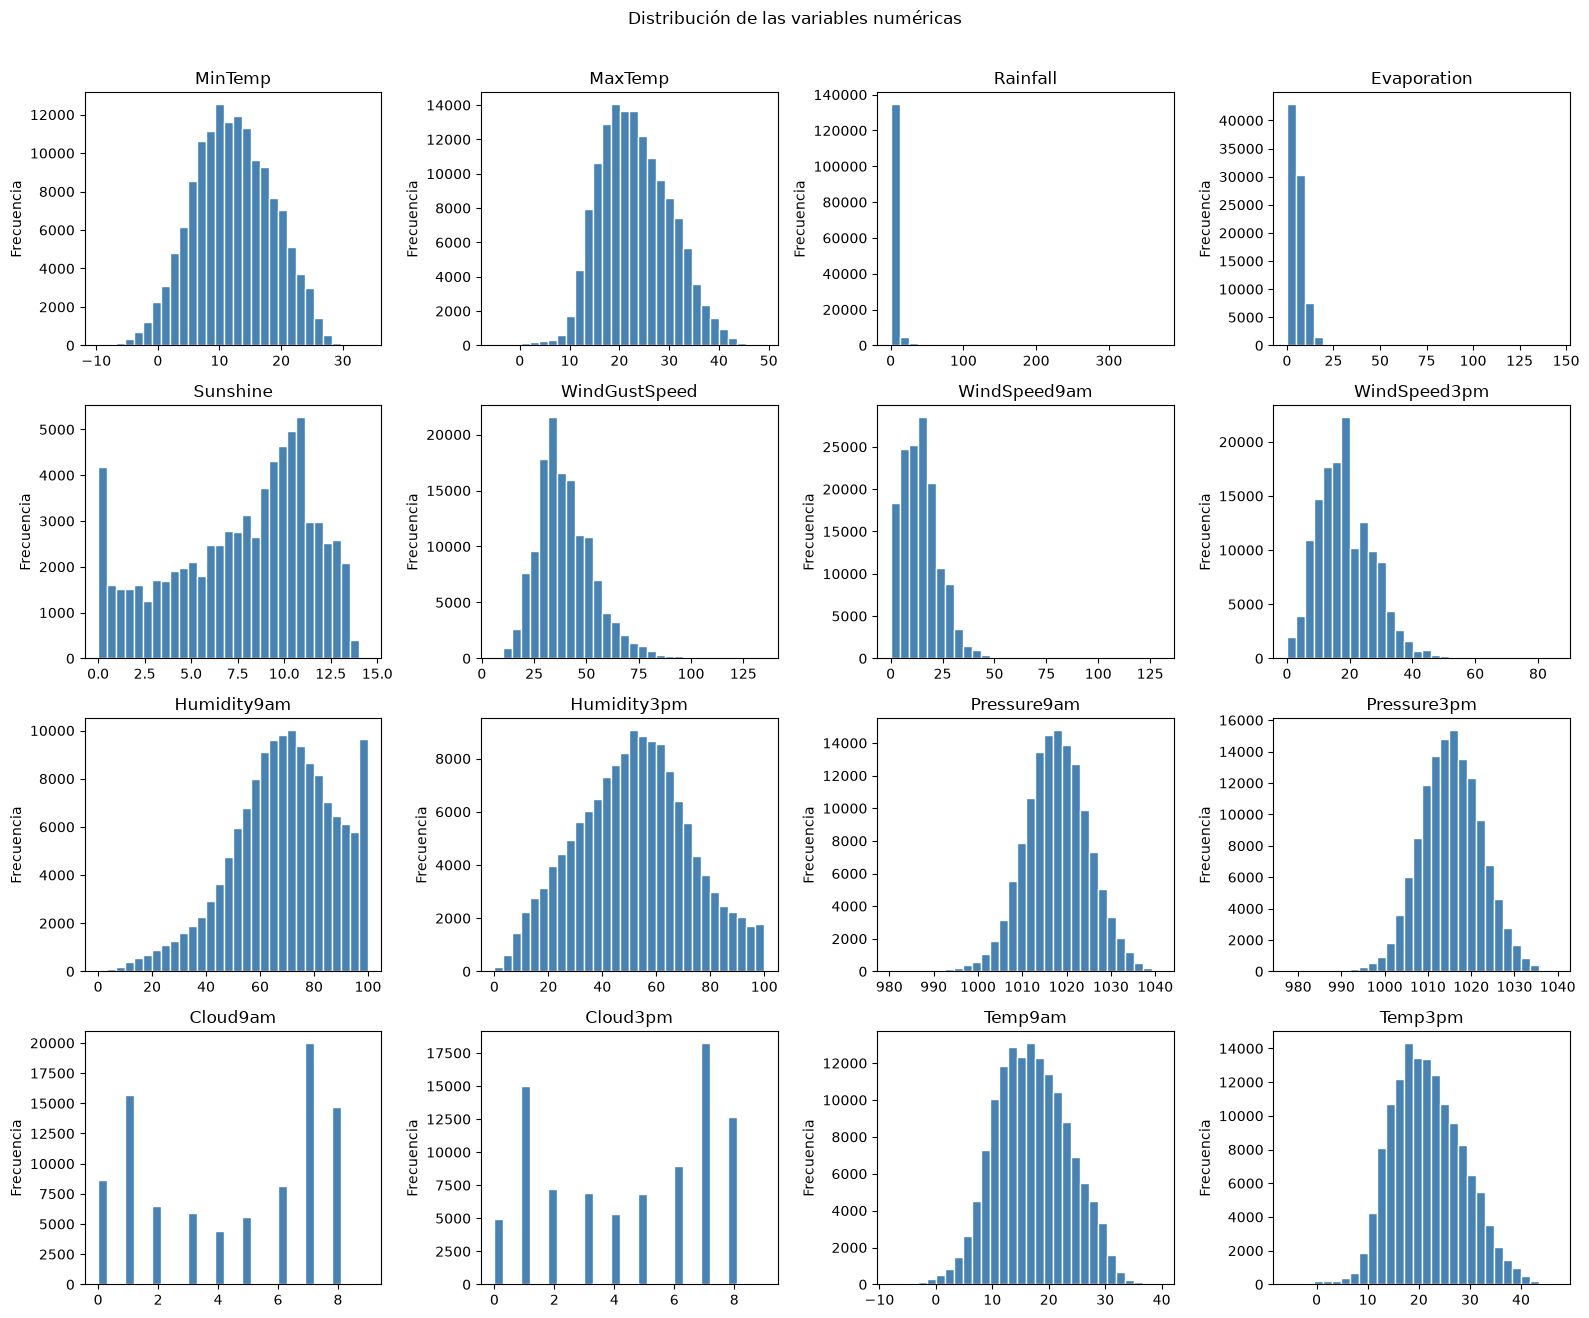

In [6]:
# Grafico las distribuciones de los predictores numéricos definidos en el EDA.
variables_hist = columnas_predictoras_numericas

fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, columna in zip(axes.flat, variables_hist):
    datos = df[columna].dropna()
    ax.hist(datos, bins=30, color="steelblue", edgecolor="white")
    ax.set_title(columna)
    ax.set_ylabel("Frecuencia")

for ax in axes.flat[len(variables_hist):]:
    ax.set_visible(False)

fig.suptitle("Distribución de las variables numéricas", y=1.01)
plt.tight_layout()
plt.show()

Para observar asociaciones entre predictores, usamos dos diagramas de dispersión. El color representa la clase observada de RainTomorrow. Se toman hasta 8.000 observaciones completas por gráfico con una semilla fija para mantener la figura legible y reproducible; este muestreo se usa únicamente para graficar.

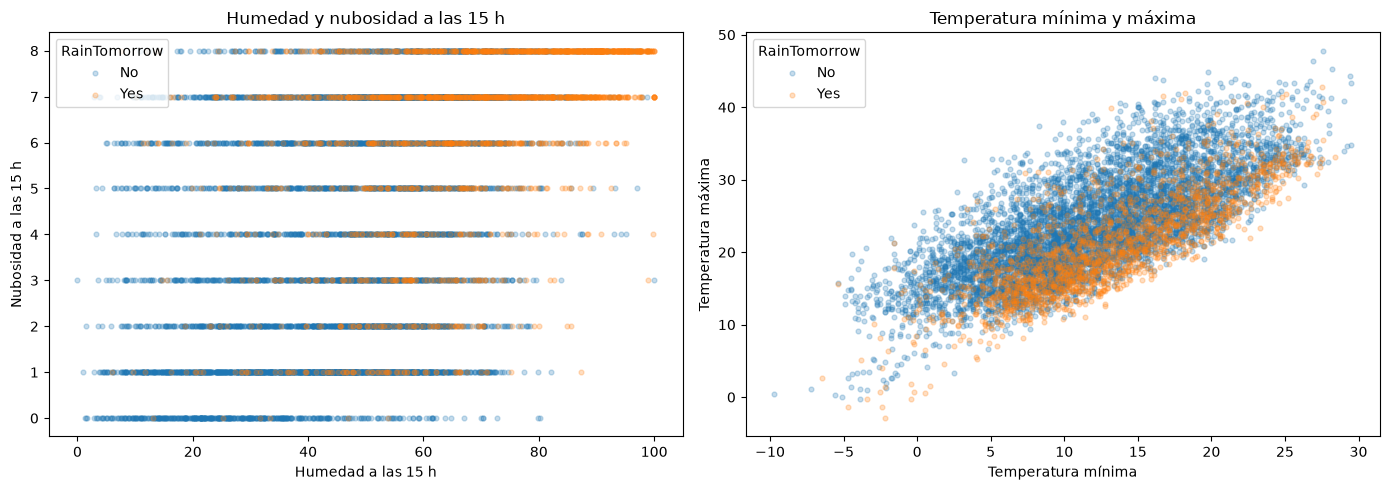

In [7]:
# Comparo humedad con nubosidad y temperatura mínima con máxima, coloreando por la clase objetivo.
colores_clase = {"No": "tab:blue", "Yes": "tab:orange"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

datos_humedad_nubes = df.dropna(subset=["Humidity3pm", "Cloud3pm", "RainTomorrow"])
if len(datos_humedad_nubes) > 8000:
    datos_humedad_nubes = datos_humedad_nubes.sample(n=8000, random_state=42)

for clase, color in colores_clase.items():
    grupo = datos_humedad_nubes[datos_humedad_nubes["RainTomorrow"] == clase]
    axes[0].scatter(
        grupo["Humidity3pm"], grupo["Cloud3pm"],
        s=12, alpha=0.25, color=color, label=clase
    )
axes[0].set_title("Humedad y nubosidad a las 15 h")
axes[0].set_xlabel("Humedad a las 15 h")
axes[0].set_ylabel("Nubosidad a las 15 h")
axes[0].legend(title="RainTomorrow", loc="upper left")

datos_temperaturas = df.dropna(subset=["MinTemp", "MaxTemp", "RainTomorrow"])
if len(datos_temperaturas) > 8000:
    datos_temperaturas = datos_temperaturas.sample(n=8000, random_state=42)

for clase, color in colores_clase.items():
    grupo = datos_temperaturas[datos_temperaturas["RainTomorrow"] == clase]
    axes[1].scatter(
        grupo["MinTemp"], grupo["MaxTemp"],
        s=12, alpha=0.25, color=color, label=clase
    )
axes[1].set_title("Temperatura mínima y máxima")
axes[1].set_xlabel("Temperatura mínima")
axes[1].set_ylabel("Temperatura máxima")
axes[1].legend(title="RainTomorrow")

plt.tight_layout()
plt.show()

Los diagramas de caja permiten comparar la mediana y el rango intercuartílico de las cuatro variables con mayor proporción de faltantes, separando las observaciones según RainTomorrow. Se ocultan los puntos extremos para que la zona central sea legible; los valores siguen presentes en el conjunto de datos. Los tamaños de muestra se indican en las etiquetas del eje horizontal.

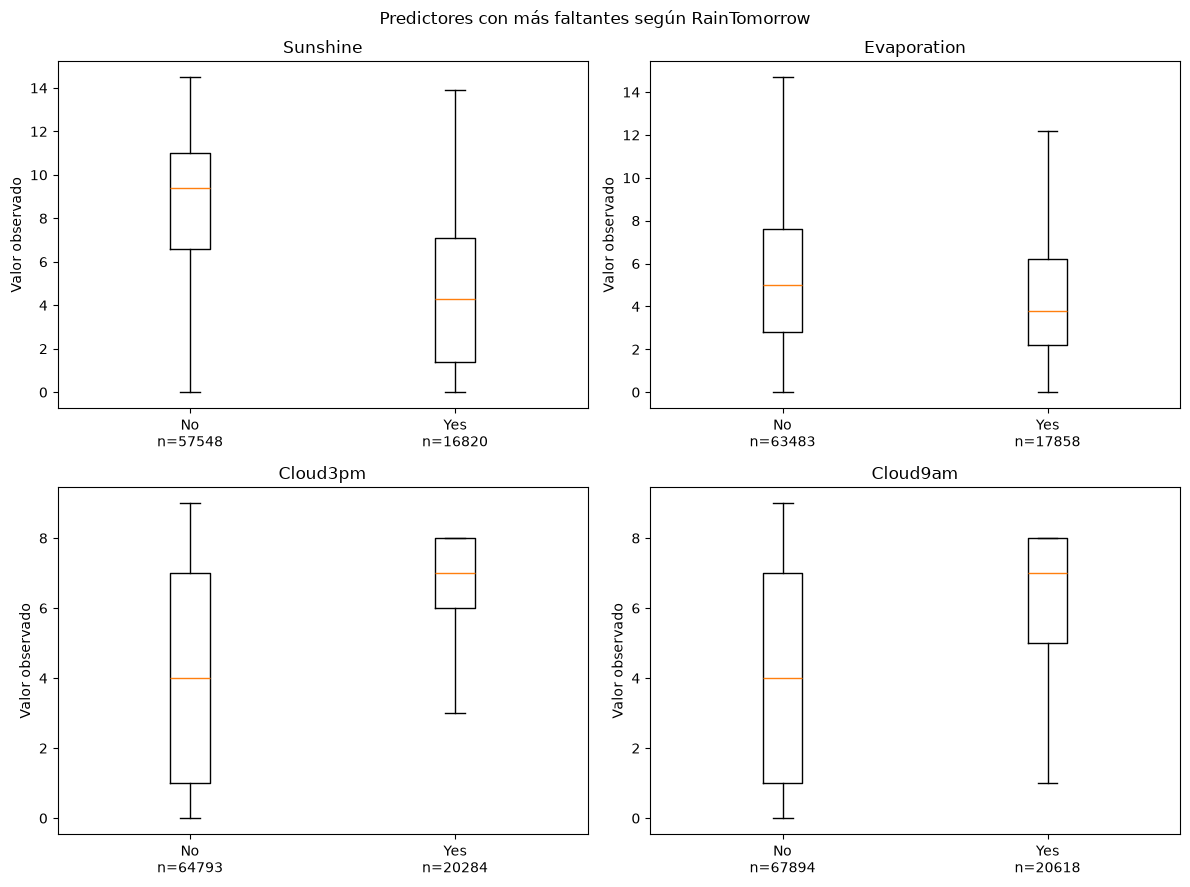

In [8]:
# Comparo por clase las distribuciones de las cuatro variables con mayor proporción de faltantes.
variables_caja = ["Sunshine", "Evaporation", "Cloud3pm", "Cloud9am"]
clases = ["No", "Yes"]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, columna in zip(axes.flat, variables_caja):
    valores_por_clase = [
        df.loc[df["RainTomorrow"] == clase, columna].dropna()
        for clase in clases
    ]
    ax.boxplot(valores_por_clase, showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels([
        f"{clase}\nn={len(valores)}"
        for clase, valores in zip(clases, valores_por_clase)
    ])
    ax.set_title(columna)
    ax.set_ylabel("Valor observado")

fig.suptitle("Predictores con más faltantes según RainTomorrow")
plt.tight_layout()
plt.show()

### Lectura de las visualizaciones

Los histogramas muestran que las variables tienen escalas y distribuciones distintas. Por ejemplo, Rainfall concentra muchas observaciones cerca de cero y presenta una cola hacia valores altos; Cloud9am y Cloud3pm toman valores discretos. Esto conviene tenerlo en cuenta al decidir el preprocesamiento.

En los diagramas de caja, la mediana de Sunshine es 9,4 horas para RainTomorrow = No y 4,3 para RainTomorrow = Yes. Para Cloud3pm y Cloud9am, las medianas son 4 y 7, respectivamente; para Evaporation, son 5 y 3,8. En los diagramas de dispersión se observa una relación creciente entre temperatura mínima y máxima, mientras que humedad y nubosidad forman bandas por los valores discretos de nubosidad. Las clases se superponen: estas figuras describen asociaciones del conjunto y no demuestran causalidad ni evalúan el desempeño de un modelo.

Los tamaños de muestra de los diagramas de caja varían porque se omiten los registros sin dato en cada predictor. No se imputaron valores para construir las figuras.

### ¿Está balanceado el dataset?

Para responderlo, observamos la distribución de la variable objetivo RainTomorrow. El cálculo usa únicamente las filas con etiqueta conocida: las observaciones sin RainTomorrow no aportan una clase al conteo y se conservan en df para las decisiones posteriores.

,cantidad,porcentaje
RainTomorrow,,
No,110281,77.58
Yes,31872,22.42


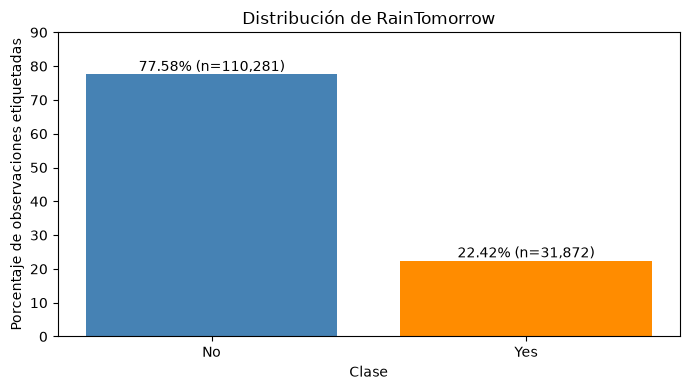

Referencia de mayoría (predecir siempre No): accuracy = 77.58%; recall de Yes = 0.00%.
Filas sin etiqueta excluidas de este conteo: 3,259.


In [9]:
# Cuento las clases conocidas y comparo su proporción con un clasificador constante de referencia.
clases_objetivo = ["No", "Yes"]
conteos_objetivo = (
    df["RainTomorrow"]
    .dropna()
    .value_counts()
    .reindex(clases_objetivo, fill_value=0)
)
total_etiquetado = conteos_objetivo.sum()
balance_objetivo = pd.DataFrame({
    "cantidad": conteos_objetivo,
    "porcentaje": conteos_objetivo / total_etiquetado * 100,
})
balance_objetivo.index.name = "RainTomorrow"
display(balance_objetivo.round({"porcentaje": 2}))

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(
    balance_objetivo.index,
    balance_objetivo["porcentaje"],
    color=["steelblue", "darkorange"],
)
for barra, porcentaje, cantidad in zip(
    barras, balance_objetivo["porcentaje"], balance_objetivo["cantidad"]
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"{porcentaje:.2f}% (n={cantidad:,})",
        ha="center",
    )
ax.set_title("Distribución de RainTomorrow")
ax.set_xlabel("Clase")
ax.set_ylabel("Porcentaje de observaciones etiquetadas")
ax.set_ylim(0, 90)
plt.tight_layout()
plt.show()

clase_mayoritaria = conteos_objetivo.idxmax()
accuracy_referencia = conteos_objetivo.max() / total_etiquetado
print(
    f"Referencia de mayoría (predecir siempre {clase_mayoritaria}): "
    f"accuracy = {accuracy_referencia:.2%}; recall de Yes = 0.00%."
)
print(f"Filas sin etiqueta excluidas de este conteo: {df['RainTomorrow'].isna().sum():,}.")

El conjunto no está balanceado respecto de la variable objetivo. Entre las 142.153 filas con etiqueta conocida, 110.281 (77,58 %) corresponden a RainTomorrow = No y 31.872 (22,42 %) a RainTomorrow = Yes; hay aproximadamente 3,46 casos de la clase mayoritaria por cada caso de la minoritaria. Las 3.259 filas sin etiqueta no se incluyen en estas proporciones.

La distribución importa porque un clasificador que siempre predijera No alcanzaría una accuracy de 77,58 %, pero tendría recall de 0 % para los días lluviosos. Por eso, como se trabaja en la unidad de métricas de clasificación, la accuracy por sí sola no alcanza para evaluar el desempeño: luego habrá que revisar métricas por clase y la matriz de confusión.


### Codificación de variables y características cíclicas

El resumen anterior describe las categorías originales. Para modelar, mantenemos `RainToday` como una categoría nominal y la codificamos con one-hot. Las direcciones del viento tienen estructura circular, por lo que las representaremos con seno y coseno. `Location` se reemplaza por latitud y longitud, y `Date` aporta dos características cíclicas del día del año. La fecha original sigue usándose para el split temporal; `RainTomorrow` es el objetivo.


In [10]:
# Resumo las variables categóricas candidatas y algunos de sus valores observados.
columnas_categoricas = [
    "Location",
    "WindGustDir",
    "WindDir9am",
    "WindDir3pm",
    "RainToday",
]
resumen_categoricas = pd.DataFrame({
    "valores distintos": df[columnas_categoricas].nunique(dropna=True),
    "faltantes": df[columnas_categoricas].isna().sum(),
    "ejemplos": {
        columna: ", ".join(
            df[columna].dropna().astype(str).unique()[:5]
        )
        for columna in columnas_categoricas
    },
})
display(resumen_categoricas)

,valores distintos,faltantes,ejemplos
Location,49,0,"Albury, BadgerysCreek, Cobar, CoffsHarbour, Moree"
WindGustDir,16,10316,"W, WNW, WSW, NE, NNW"
WindDir9am,16,10562,"W, NNW, SE, ENE, SW"
WindDir3pm,16,4226,"WNW, WSW, E, NW, W"
RainToday,2,3260,"No, Yes"


`RainToday` no tiene orden natural, así que conservamos `pd.get_dummies` solo para esta variable. Para las tres direcciones del viento usamos un ángulo de brújula y las componentes seno/coseno: así se representa la proximidad circular sin asignarles un orden lineal. Sumamos un indicador por dirección para conservar los faltantes.

`Location` se transforma en latitud y longitud, con coordenadas aproximadas para las 49 estaciones. `Date` se transforma en seno y coseno del día del año objetivo (el día siguiente a la observación). La tabla de coordenadas corresponde a la Tabla 4 de [este trabajo sobre WeatherAUS](https://pmc.ncbi.nlm.nih.gov/articles/PMC12453857/); las latitudes se expresan con signo negativo porque las estaciones están al sur del ecuador.

La elección sigue el tema de *feature engineering* de la cátedra: la [clase de regularización](../../../Catedra/Unidad_2/Clase%205%20-%20Regularización.pptx) y el [notebook de regularización con vehículos](../../../Catedra/Unidad_2/notebooks/3_Regularizacion_vehiculos_data.ipynb) discuten el costo de muchas variables y las dummies en modelos lineales. La [clase de clasificación](../../../Catedra/Unidad_3/Clase%207%20-%20Modelos%20lineales%20para%20Clasificación.pptx) advierte contra asignar códigos ordinales arbitrarios a categorías; acá el ángulo de brújula expresa su estructura circular. La [clase de selección y validación](../../../Catedra/Unidad_4/Clase%2011%20-%20Selección%20y%20validación%20de%20modelos.pptx) incluye la estacionalidad anual en series.


### Matriz de correlación de variables

Calculamos correlaciones de Pearson entre los predictores numéricos y la etiqueta. Para incluir RainTomorrow en el análisis, usamos una copia temporal con No = 0 y Yes = 1; esta codificación solo se utiliza en la matriz, no modifica df ni reemplaza la codificación prevista para el modelo.

Las filas sin RainTomorrow conocido se excluyen de esta matriz. No imputamos los faltantes: pandas calcula cada correlación con las observaciones disponibles para ese par, por lo que la cantidad de observaciones puede variar entre pares.

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainTomorrow
MinTemp,1.00,0.73,0.10,0.47,0.07,0.18,0.17,0.17,-0.23,0.01,-0.45,-0.46,0.08,0.02,0.90,0.70,0.08
MaxTemp,0.73,1.00,-0.07,0.59,0.47,0.07,0.01,0.05,-0.50,-0.51,-0.33,-0.43,-0.29,-0.28,0.88,0.98,-0.16
Rainfall,0.10,-0.07,1.00,-0.06,-0.23,0.13,0.09,0.06,0.22,0.25,-0.17,-0.13,0.20,0.17,0.01,-0.08,0.24
Evaporation,0.47,0.59,-0.06,1.00,0.37,0.20,0.19,0.13,-0.50,-0.39,-0.27,-0.29,-0.19,-0.18,0.54,0.57,-0.12
Sunshine,0.07,0.47,-0.23,0.37,1.00,-0.03,0.01,0.06,-0.49,-0.63,0.04,-0.02,-0.68,-0.70,0.29,0.49,-0.45
WindGustSpeed,0.18,0.07,0.13,0.20,-0.03,1.00,0.60,0.68,-0.21,-0.03,-0.46,-0.41,0.07,0.11,0.15,0.03,0.23
WindSpeed9am,0.17,0.01,0.09,0.19,0.01,0.60,1.00,0.51,-0.27,-0.03,-0.23,-0.17,0.02,0.05,0.13,0.00,0.09
WindSpeed3pm,0.17,0.05,0.06,0.13,0.06,0.68,0.51,1.00,-0.14,0.02,-0.29,-0.25,0.05,0.03,0.16,0.03,0.09
Humidity9am,-0.23,-0.50,0.22,-0.50,-0.49,-0.21,-0.27,-0.14,1.00,0.66,0.14,0.19,0.45,0.36,-0.47,-0.50,0.26
Humidity3pm,0.01,-0.51,0.25,-0.39,-0.63,-0.03,-0.03,0.02,0.66,1.00,-0.03,0.05,0.52,0.52,-0.22,-0.56,0.44


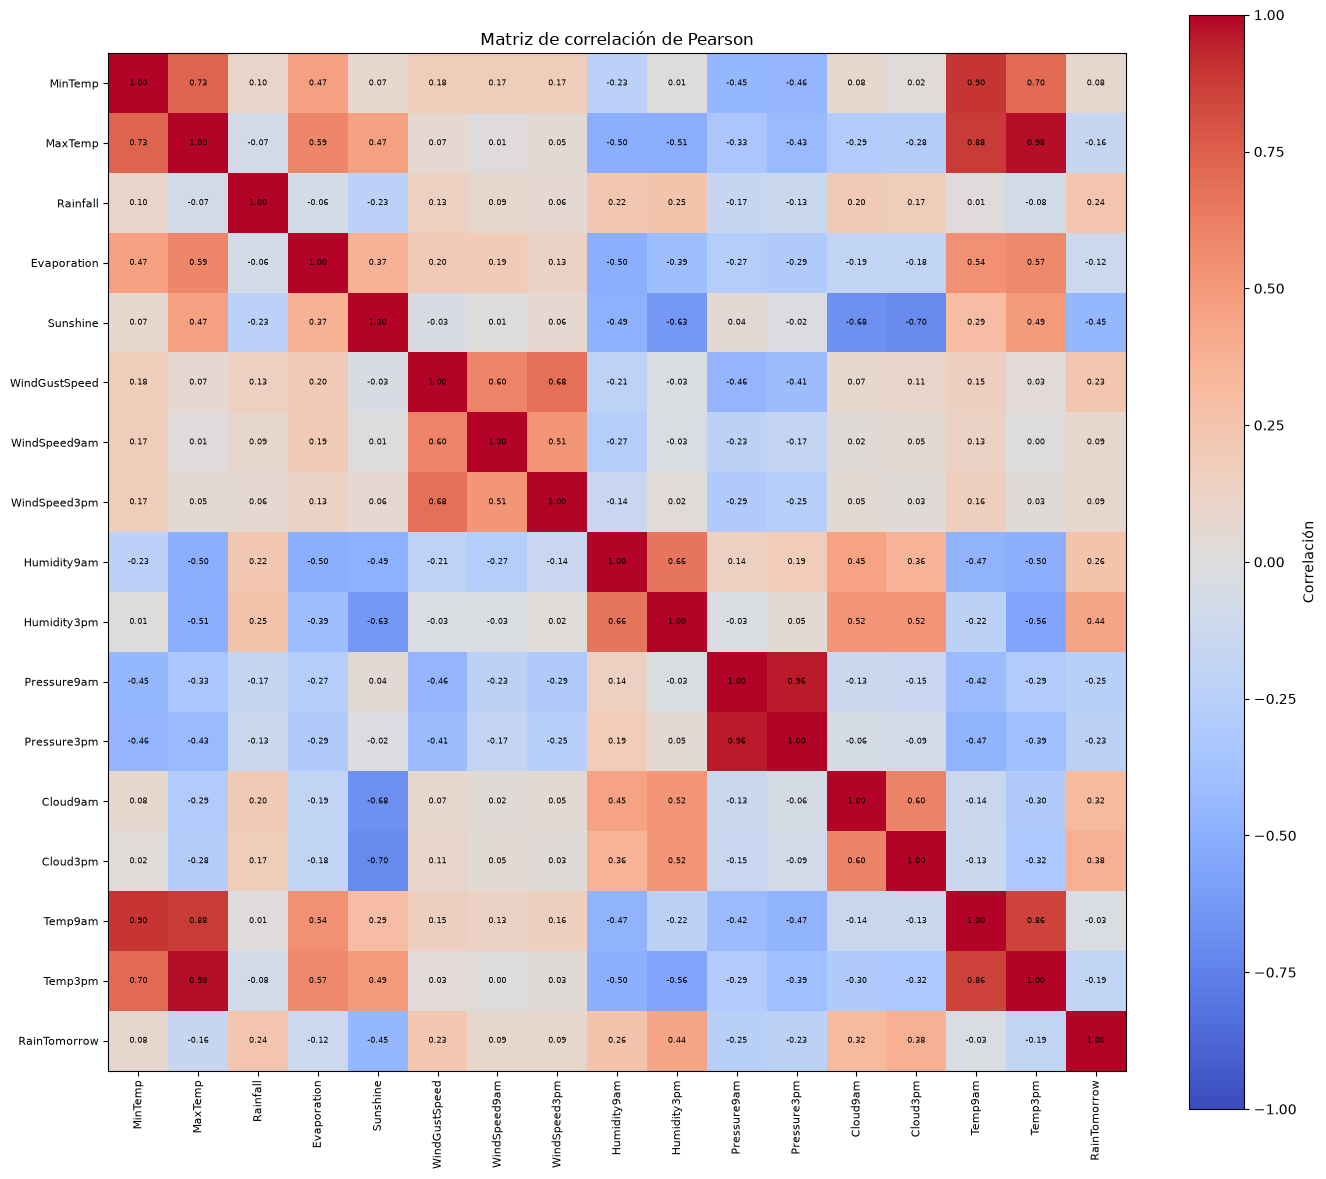

,correlación con RainTomorrow,observaciones válidas
Sunshine,-0.451,74368
Humidity3pm,0.445,138544
Cloud3pm,0.382,85077
Cloud9am,0.317,88512
Humidity9am,0.256,140379
Pressure9am,-0.246,128143
Rainfall,0.239,140747
WindGustSpeed,0.233,132885
Pressure3pm,-0.226,128176
Temp3pm,-0.192,139428


In [11]:
# Calculo y grafico las correlaciones de Pearson sin modificar el conjunto original.
variables_numericas = columnas_predictoras_numericas
datos_correlacion = df.loc[
    df["RainTomorrow"].notna(), variables_numericas
].copy()
datos_correlacion["RainTomorrow"] = (
    df.loc[df["RainTomorrow"].notna(), "RainTomorrow"]
    .map({"No": 0, "Yes": 1})
)

matriz_correlacion = datos_correlacion.corr(method="pearson")
display(matriz_correlacion.round(2))

fig, ax = plt.subplots(figsize=(14, 12))
imagen = ax.imshow(
    matriz_correlacion,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
etiquetas = matriz_correlacion.columns
ax.set_xticks(range(len(etiquetas)))
ax.set_yticks(range(len(etiquetas)))
ax.set_xticklabels(etiquetas, rotation=90, fontsize=8)
ax.set_yticklabels(etiquetas, fontsize=8)
for fila in range(len(etiquetas)):
    for columna in range(len(etiquetas)):
        ax.text(
            columna,
            fila,
            f"{matriz_correlacion.iloc[fila, columna]:.2f}",
            ha="center",
            va="center",
            fontsize=6,
        )
ax.set_title("Matriz de correlación de Pearson")
fig.colorbar(imagen, ax=ax, label="Correlación")
plt.tight_layout()
plt.show()

asociaciones_objetivo = pd.DataFrame({
    "correlación con RainTomorrow": matriz_correlacion["RainTomorrow"].drop("RainTomorrow"),
    "observaciones válidas": datos_correlacion.drop(columns="RainTomorrow").count(),
})
orden = asociaciones_objetivo["correlación con RainTomorrow"].abs().sort_values(
    ascending=False
).index
display(asociaciones_objetivo.loc[orden].round(3))

La matriz muestra asociaciones lineales que pueden orientar la comprensión del conjunto. Las correlaciones más altas con RainTomorrow son Sunshine (−0,451), Humidity3pm (0,445), Cloud3pm (0,382) y Cloud9am (0,317). Entre predictores, MaxTemp y Temp3pm presentan una correlación de 0,98, y Pressure9am y Pressure3pm una de 0,96; son mediciones relacionadas y podrían aportar información parcialmente redundante.

Estas asociaciones no implican causalidad ni bastan, por sí solas, para eliminar variables. La matriz también debe leerse considerando que cada par puede usar una cantidad distinta de filas debido a los faltantes. La correlación de Pearson resume relaciones lineales y puede no describir relaciones más complejas.

### Estandarización y escalado de datos

Los predictores numéricos originales y derivados tienen unidades y rangos distintos, y algunos presentan valores extremos. Usamos `RobustScaler`, que centra con la mediana y escala por el rango intercuartílico. Los predictores derivados de fecha, viento y ubicación también pasan por el escalador; los faltantes de viento se codifican con un indicador aparte.

Como queremos predecir días futuros, reservamos para prueba el tramo cronológico más reciente. Ajustamos el escalador solo con entrenamiento y luego lo aplicamos a prueba. `RainToday` se trata por separado como variable categórica.


In [12]:
# Derivo coordenadas, direcciones cíclicas y estacionalidad antes de separar los datos.
# Latitudes negativas: las 49 ubicaciones están en el hemisferio sur; longitudes positivas: al este.
coordenadas_por_ubicacion = {
    "Adelaide": (-34.93, 138.60), "Albany": (-35.03, 117.88),
    "Albury": (-36.07, 146.91), "AliceSprings": (-23.70, 133.88),
    "BadgerysCreek": (-33.88, 150.76), "Ballarat": (-37.56, 143.85),
    "Bendigo": (-36.76, 144.28), "Brisbane": (-27.47, 153.03),
    "Cairns": (-16.92, 145.77), "Canberra": (-35.28, 149.13),
    "Cobar": (-31.50, 145.84), "CoffsHarbour": (-30.30, 153.11),
    "Dartmoor": (-37.92, 141.27), "Darwin": (-12.46, 130.85),
    "GoldCoast": (-28.02, 153.40), "Hobart": (-42.88, 147.33),
    "Katherine": (-14.45, 132.27), "Launceston": (-41.43, 147.14),
    "Melbourne": (-37.81, 144.96), "MelbourneAirport": (-37.67, 144.84),
    "Mildura": (-34.21, 142.13), "Moree": (-29.46, 149.84),
    "MountGambier": (-37.83, 140.78), "MountGinini": (-35.53, 148.77),
    "Newcastle": (-32.93, 151.78), "Nhil": (-36.33, 141.65),
    "NorahHead": (-33.28, 151.57), "NorfolkIsland": (-29.04, 167.95),
    "Nuriootpa": (-34.47, 139.00), "PearceRAAF": (-31.67, 116.02),
    "Penrith": (-33.75, 150.69), "Perth": (-31.95, 115.86),
    "PerthAirport": (-31.94, 115.97), "Portland": (-38.34, 141.60),
    "Richmond": (-37.82, 144.99), "Sale": (-38.11, 147.07),
    "SalmonGums": (-32.98, 121.65), "Sydney": (-33.87, 151.21),
    "SydneyAirport": (-33.95, 151.18), "Townsville": (-19.26, 146.82),
    "Tuggeranong": (-35.42, 149.07), "Uluru": (-25.34, 131.04),
    "WaggaWagga": (-35.12, 147.37), "Walpole": (-34.98, 116.73),
    "Watsonia": (-37.71, 145.08), "Williamtown": (-32.81, 151.84),
    "Witchcliffe": (-34.02, 115.10), "Wollongong": (-34.42, 150.89),
    "Woomera": (-31.20, 136.83),
}
direcciones_viento = [
    "N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
    "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW",
]
columnas_direcciones_viento = ["WindGustDir", "WindDir9am", "WindDir3pm"]
columnas_categoricas_modelo = ["RainToday"]
columnas_coordenadas = ["Location_latitud", "Location_longitud"]
columnas_fecha_ciclica = ["Date_sin", "Date_cos"]
columnas_viento_ciclico = [
    f"{columna}_{componente}"
    for columna in columnas_direcciones_viento
    for componente in ("sin", "cos", "faltante")
]
columnas_numericas_modelo = [
    *columnas_predictoras_numericas,
    *columnas_coordenadas,
    *columnas_fecha_ciclica,
    *columnas_viento_ciclico,
]

# Separo cronológicamente las filas etiquetadas; Date no entra como fecha absoluta al modelo.
datos_etiquetados = df.loc[df["RainTomorrow"].notna()].copy()
X = datos_etiquetados[columnas_predictoras_numericas].copy()
y = datos_etiquetados["RainTomorrow"].copy()

coordenadas = datos_etiquetados["Location"].map(coordenadas_por_ubicacion)
if coordenadas.isna().any():
    ubicaciones_sin_coordenadas = sorted(datos_etiquetados.loc[coordenadas.isna(), "Location"].unique())
    raise ValueError(f"Faltan coordenadas para estas ubicaciones: {ubicaciones_sin_coordenadas}")
X["Location_latitud"] = coordenadas.map(lambda punto: punto[0])
X["Location_longitud"] = coordenadas.map(lambda punto: punto[1])

# RainTomorrow corresponde al día siguiente, así que la fase anual representa ese día objetivo.
fecha_objetivo = datos_etiquetados["Date"] + pd.Timedelta(days=1)
dia_del_anio = fecha_objetivo.dt.dayofyear - 1
angulo_anual = 2 * np.pi * dia_del_anio / 365.25
X["Date_sin"] = np.sin(angulo_anual)
X["Date_cos"] = np.cos(angulo_anual)

# La brújula avanza en sentido horario desde N; el par seno/coseno conserva la circularidad.
indice_direccion = {direccion: indice for indice, direccion in enumerate(direcciones_viento)}
for columna in columnas_direcciones_viento:
    indice = datos_etiquetados[columna].map(indice_direccion)
    direcciones_desconocidas = set(datos_etiquetados[columna].dropna()) - set(indice_direccion)
    if direcciones_desconocidas:
        raise ValueError(f"Direcciones no reconocidas en {columna}: {sorted(direcciones_desconocidas)}")
    angulo = 2 * np.pi * indice / len(direcciones_viento)
    X[f"{columna}_sin"] = np.sin(angulo).fillna(0)
    X[f"{columna}_cos"] = np.cos(angulo).fillna(0)
    X[f"{columna}_faltante"] = indice.isna().astype(int)

X["RainToday"] = datos_etiquetados["RainToday"]
columnas_predictoras = columnas_numericas_modelo + columnas_categoricas_modelo
X = X[columnas_predictoras]

fecha_corte = datos_etiquetados["Date"].quantile(0.80)
mascara_entrenamiento = datos_etiquetados["Date"] <= fecha_corte
X_train = X.loc[mascara_entrenamiento].copy()
X_test = X.loc[~mascara_entrenamiento].copy()
y_train = y.loc[mascara_entrenamiento].copy()
y_test = y.loc[~mascara_entrenamiento].copy()

pipeline_escalado = Pipeline(steps=[("escalador", RobustScaler())])
X_train_escalado = X_train.copy()
X_test_escalado = X_test.copy()
X_train_escalado.loc[:, columnas_numericas_modelo] = pipeline_escalado.fit_transform(
    X_train[columnas_numericas_modelo]
)
X_test_escalado.loc[:, columnas_numericas_modelo] = pipeline_escalado.transform(
    X_test[columnas_numericas_modelo]
)

resumen_train_escalado = (
    X_train_escalado[columnas_numericas_modelo]
    .describe()
    .T[["min", "50%", "max"]]
    .round(2)
)
resumen_test_escalado = (
    X_test_escalado[columnas_numericas_modelo]
    .describe()
    .T[["min", "50%", "max"]]
    .round(2)
)
display(pd.concat({
    "Entrenamiento escalado": resumen_train_escalado,
    "Prueba escalada": resumen_test_escalado,
}, axis=1))


Entrenamiento escalado              Prueba escalada  \
                                        min  50%     max             min   
MinTemp                               -2.34  0.0    2.42           -2.21   
MaxTemp                               -2.59  0.0    2.65           -2.71   
Rainfall                               0.00  0.0  463.75            0.00   
Evaporation                           -1.00  0.0   16.91           -1.00   
Sunshine                              -1.45  0.0    1.02           -1.45   
WindGustSpeed                         -1.88  0.0    5.71           -1.88   
WindSpeed9am                          -1.08  0.0    6.25           -1.08   
WindSpeed3pm                          -1.50  0.0    5.67           -1.50   
Humidity9am                           -2.66  0.0    1.15           -2.62   
Humidity3pm                           -1.80  0.0    1.66           -1.75   
Pressure9am                           -3.91  0.0    2.44           -3.78   
Pressure3pm                           -3.69  0.0    2.54           -3.96   
Cloud9am                              -0.83  0.0    0.67           -0.83   
Cloud3pm                              -1.00  0.0    0.80           -1.00   
Temp9am                               -2.50  0.0    2.53           -2.66   
Temp3pm                               -2.65  0.0    2.68           -2.75   
Location_latitud                      -1.68  0.0    4.10           -1.68   
Location_longitud                     -2.54  0.0    1.83           -2.54   
Date_sin                              -0.69  0.0    0.70           -0.69   
Date_cos                              -0.69  0.0    0.75           -0.69   
WindGustDir_sin                       -0.71  0.0    0.71           -0.71   
WindGustDir_cos                       -0.71  0.0    0.71           -0.71   
WindGustDir_faltante                   0.00  0.0    1.00            0.00   
WindDir9am_sin                        -0.71  0.0    0.71           -0.71   
WindDir9am_cos                        -0.71  0.0    0.71           -0.71   
WindDir9am_faltante                    0.00  0.0    1.00            0.00   
WindDir3pm_sin                        -0.71  0.0    0.71           -0.71   
WindDir3pm_cos                        -0.71  0.0    0.71           -0.71   
WindDir3pm_faltante                    0.00  0.0    1.00            0.00   

                                    
                       50%     max  
MinTemp               0.13    2.15  
MaxTemp               0.16    2.50  
Rainfall              0.00  281.25  
Evaporation           0.22   30.52  
Sunshine              0.05    1.05  
WindGustSpeed         0.00    4.94  
WindSpeed9am          0.00    9.75  
WindSpeed3pm          0.00    3.83  
Humidity9am           0.01    1.15  
Humidity3pm          -0.00    1.66  
Pressure9am          -0.08    2.35  
Pressure3pm          -0.08    2.19  
Cloud9am              0.17    0.50  
Cloud3pm              0.20    0.60  
Temp9am               0.13    2.33  
Temp3pm               0.13    2.69  
Location_latitud      0.00    4.10  
Location_longitud    -0.06    1.83  
Date_sin              0.21    0.70  
Date_cos              0.15    0.75  
WindGustDir_sin       0.00    0.71  
WindGustDir_cos      -0.00    0.71  
WindGustDir_faltante  0.00    1.00  
WindDir9am_sin        0.00    0.71  
WindDir9am_cos        0.00    0.71  
WindDir9am_faltante   0.00    1.00  
WindDir3pm_sin        0.00    0.71  
WindDir3pm_cos        0.00    0.71  
WindDir3pm_faltante   0.00    1.00

### Validación train-test

La tabla permite revisar el período y la proporción de clases en cada conjunto. El tramo de prueba corresponde a fechas posteriores a las usadas para entrenar y queda reservado para la evaluación final. Si más adelante ajustamos hiperparámetros, la validación cruzada se hará dentro de entrenamiento para no usar el conjunto de prueba durante esa selección.

In [13]:
# Compruebo el período y la proporción de clases en cada conjunto.
fechas_train = datos_etiquetados.loc[X_train.index, "Date"]
fechas_test = datos_etiquetados.loc[X_test.index, "Date"]
resumen_validacion = pd.DataFrame({
    "filas": [len(X_train), len(X_test)],
    "fecha inicial": [fechas_train.min().date(), fechas_test.min().date()],
    "fecha final": [fechas_train.max().date(), fechas_test.max().date()],
    "RainTomorrow = No (%)": [
        (y_train == "No").mean() * 100,
        (y_test == "No").mean() * 100,
    ],
    "RainTomorrow = Yes (%)": [
        (y_train == "Yes").mean() * 100,
        (y_test == "Yes").mean() * 100,
    ],
}, index=["Entrenamiento", "Prueba"])
display(resumen_validacion.round({
    "RainTomorrow = No (%)": 2,
    "RainTomorrow = Yes (%)": 2,
}))

,filas,fecha inicial,fecha final,RainTomorrow = No (%),RainTomorrow = Yes (%)
Entrenamiento,113748,2007-11-01,2015-11-09,77.56,22.44
Prueba,28405,2015-11-10,2017-06-24,77.67,22.33


El corte queda en el 9 de noviembre de 2015: entrenamiento reúne 113.748 filas hasta esa fecha y prueba 28.405 filas desde el día siguiente. La proporción de RainTomorrow = Yes es 22,44 % en entrenamiento y 22,33 % en prueba; la de No es 77,56 % y 77,67 %, respectivamente. La partición respeta el orden temporal: entrenamiento incluye las fechas anteriores al corte y prueba, las posteriores. Las proporciones de clases son similares en ambos períodos.

## 2. Regresión logística

### Preprocesamiento

En las variables numéricas originales y derivadas imputamos los faltantes con la mediana de entrenamiento. En las tres direcciones del viento, los rumbos faltantes se representan con seno y coseno iguales a cero y un indicador separado; para las variables meteorológicas numéricas usamos la mediana escalada de entrenamiento.

`RainToday` sigue siendo categórica: sus faltantes se reemplazan por `Faltante` y usamos `pd.get_dummies` con `drop_first=True`. La tabla de coordenadas cubre las 49 ubicaciones del CSV. En la búsqueda de hiperparámetros, las mismas reglas se ajustan dentro de cada fold mediante un `Pipeline`.


In [14]:
# Imputo los predictores numéricos con valores de entrenamiento y codifico RainToday.
y_train_bin = (y_train == "Yes").astype(int)
y_test_bin = (y_test == "Yes").astype(int)

medianas_train = X_train_escalado[columnas_numericas_modelo].median()
X_train_prep = X_train_escalado.copy()
X_test_prep = X_test_escalado.copy()
X_train_prep[columnas_numericas_modelo] = X_train_prep[columnas_numericas_modelo].fillna(medianas_train)
X_test_prep[columnas_numericas_modelo] = X_test_prep[columnas_numericas_modelo].fillna(medianas_train)

X_train_prep[columnas_categoricas_modelo] = X_train_prep[columnas_categoricas_modelo].fillna("Faltante")
X_test_prep[columnas_categoricas_modelo] = X_test_prep[columnas_categoricas_modelo].fillna("Faltante")

X_train_prep = pd.get_dummies(
    X_train_prep,
    columns=columnas_categoricas_modelo,
    drop_first=True,
    dtype=int,
)
X_test_prep = pd.get_dummies(
    X_test_prep,
    columns=columnas_categoricas_modelo,
    drop_first=True,
    dtype=int,
)
X_test_prep = X_test_prep.reindex(columns=X_train_prep.columns, fill_value=0)

print("Entrenamiento:", X_train_prep.shape, "Prueba:", X_test_prep.shape)


Entrenamiento: (113748, 31) Prueba: (28405, 31)


In [15]:
# Cuento las columnas one-hot que aún necesita RainToday.
conteo_dummies = pd.Series({
    columna: X_train_prep.columns.str.startswith(columna + "_").sum()
    for columna in columnas_categoricas_modelo
}, name="columnas")
display(conteo_dummies.to_frame())
print(
    "Numéricas originales:", len(columnas_predictoras_numericas),
    "| Derivadas de Location/Date/viento:", len(columnas_numericas_modelo) - len(columnas_predictoras_numericas),
    "| Dummies:", conteo_dummies.sum(),
)


,columnas
RainToday,2


Numéricas originales: 16 | Derivadas de Location/Date/viento: 13 | Dummies: 2


Tras el preprocesamiento quedan **31 columnas**: 16 predictores numéricos originales, 13 columnas derivadas (2 coordenadas, 2 de fecha y 9 de viento) y 2 dummies de `RainToday`. Antes quedaban 114 columnas: 16 numéricas y 98 dummies. La reducción refleja la estructura cíclica y geográfica de los datos; las 3 direcciones se representan con pares seno/coseno y un indicador de faltante cada una.


### Entrenamiento

Entrenamos dos regresiones logísticas sobre los predictores preprocesados. La primera usa `class_weight=None`; la segunda usa `class_weight="balanced"`, que asigna más peso a los errores en la clase minoritaria `Yes`. Comparamos cuánto cambia la detección de días lluviosos.

Fijamos `max_iter=1000` como límite. Con las nuevas representaciones ambos ajustes convergen antes de ese límite: 87 iteraciones para la logística estándar y 95 para la balanceada.


In [16]:
# Entreno dos regresiones logísticas: una estándar y otra que compensa el desbalance.
modelos = {
    "Logística": LogisticRegression(max_iter=1000),
    "Logística balanceada": LogisticRegression(max_iter=1000, class_weight="balanced"),
}
for nombre, modelo in modelos.items():
    modelo.fit(X_train_prep, y_train_bin)
    print(f"{nombre}: {modelo.n_iter_[0]} iteraciones")

Logística: 87 iteraciones


Logística balanceada: 95 iteraciones


### Métricas

Como el dataset está desbalanceado, no alcanza con la accuracy. Calculamos precision, recall y F1 de la clase Yes, que es la que nos interesa detectar, el recall de la clase No y el AUC, que no depende del umbral.

Además investigamos tres métricas pensadas para clases desbalanceadas, a partir de la documentación de scikit-learn (https://scikit-learn.org/stable/modules/model_evaluation.html):

- Balanced accuracy: promedio del recall de cada clase. Un modelo que predice siempre No obtiene 0,5, mientras que su accuracy sería 0,78.
- Coeficiente de correlación de Matthews (MCC): usa las cuatro celdas de la matriz de confusión, (VP·VN − FP·FN) / √((VP+FP)(VP+FN)(VN+FP)(VN+FN)). Va de −1 a 1, vale 0 para un modelo que no es mejor que predecir una clase constante y solo es alto si el modelo acierta bien en ambas clases.
- Average precision: resume la curva precision-recall en un número. A diferencia del AUC, no usa los verdaderos negativos, así que no se ve favorecida por la gran cantidad de días sin lluvia. Su valor de referencia es la proporción de Yes (0,22).

Medimos todo en entrenamiento y en prueba para después comparar ambos conjuntos y evaluar el fitting.

In [17]:
# Calculo las métricas de cada modelo en entrenamiento y prueba.
conjuntos = {
    "Entrenamiento": (X_train_prep, y_train_bin),
    "Prueba": (X_test_prep, y_test_bin),
}
filas_metricas = []
for nombre, modelo in modelos.items():
    for conjunto, (X_conjunto, y_conjunto) in conjuntos.items():
        y_pred = modelo.predict(X_conjunto)
        y_prob = modelo.predict_proba(X_conjunto)[:, 1]
        filas_metricas.append({
            "modelo": nombre,
            "conjunto": conjunto,
            "accuracy": accuracy_score(y_conjunto, y_pred),
            "precision (Yes)": precision_score(y_conjunto, y_pred),
            "recall (Yes)": recall_score(y_conjunto, y_pred),
            "F1 (Yes)": f1_score(y_conjunto, y_pred),
            "recall (No)": recall_score(y_conjunto, y_pred, pos_label=0),
            "AUC": roc_auc_score(y_conjunto, y_prob),
            "balanced accuracy": balanced_accuracy_score(y_conjunto, y_pred),
            "MCC": matthews_corrcoef(y_conjunto, y_pred),
            "average precision": average_precision_score(y_conjunto, y_prob),
        })

metricas = pd.DataFrame(filas_metricas).set_index(["modelo", "conjunto"])
display(metricas.round(3))

accuracy  precision (Yes)  recall (Yes)  \
modelo               conjunto                                                 
Logística            Entrenamiento     0.845            0.719         0.509   
                     Prueba            0.841            0.722         0.471   
Logística balanceada Entrenamiento     0.791            0.523         0.777   
                     Prueba            0.792            0.525         0.752   

                                    F1 (Yes)  recall (No)    AUC  \
modelo               conjunto                                      
Logística            Entrenamiento     0.596        0.943  0.871   
                     Prueba            0.570        0.948  0.859   
Logística balanceada Entrenamiento     0.626        0.795  0.871   
                     Prueba            0.618        0.804  0.859   

                                    balanced accuracy    MCC  \
modelo               conjunto                                  
Logística            Entrenamiento              0.726  0.516   
                     Prueba                     0.709  0.495   
Logística balanceada Entrenamiento              0.786  0.507   
                     Prueba                     0.778  0.497   

                                    average precision  
modelo               conjunto                          
Logística            Entrenamiento              0.697  
                     Prueba                     0.675  
Logística balanceada Entrenamiento              0.695  
                     Prueba                     0.673

In [18]:
# Muestro precision, recall y F1 de ambas clases para cada modelo en prueba.
for nombre, modelo in modelos.items():
    print(nombre)
    print(classification_report(y_test_bin, modelo.predict(X_test_prep), target_names=["No", "Yes"]))

Logística
              precision    recall  f1-score   support

          No       0.86      0.95      0.90     22061
         Yes       0.72      0.47      0.57      6344

    accuracy                           0.84     28405
   macro avg       0.79      0.71      0.74     28405
weighted avg       0.83      0.84      0.83     28405

Logística balanceada
              precision    recall  f1-score   support

          No       0.92      0.80      0.86     22061
         Yes       0.52      0.75      0.62      6344

    accuracy                           0.79     28405
   macro avg       0.72      0.78      0.74     28405
weighted avg       0.83      0.79      0.80     28405



En prueba, la regresión logística estándar alcanza accuracy 0,841, por encima de la referencia de predecir siempre `No` (77,67 %). Su recall de `Yes` es 0,471: detecta algo menos de la mitad de los días lluviosos. La versión balanceada baja la accuracy a 0,792, pero sube el recall de `Yes` a 0,752. A cambio, la precision de `Yes` baja de 0,722 a 0,525 y aumentan las falsas alarmas. El F1 de `Yes` pasa de 0,570 a 0,618.

El AUC de prueba es 0,859 en ambos modelos. Sus capacidades de ordenar los casos por probabilidad son muy parecidas; lo que cambia principalmente es el punto de corte de clasificación.

Las métricas para clases desbalanceadas muestran el mismo intercambio: la balanced accuracy favorece al modelo balanceado (0,778 contra 0,709), mientras que MCC es casi igual (0,497 y 0,495) y average precision también (0,673 y 0,675). La codificación reducida conserva un desempeño similar entre los dos modelos; el umbral permite ajustar el balance entre falsos negativos y falsas alarmas.


### Matrices de confusión

Tomamos Yes como clase positiva. En la matriz, las filas indican el valor real y las columnas la predicción. Un falso positivo es un día en que el modelo predijo lluvia y no llovió (falsa alarma). Un falso negativo es un día en que llovió y el modelo predijo que no (lluvia sin aviso).

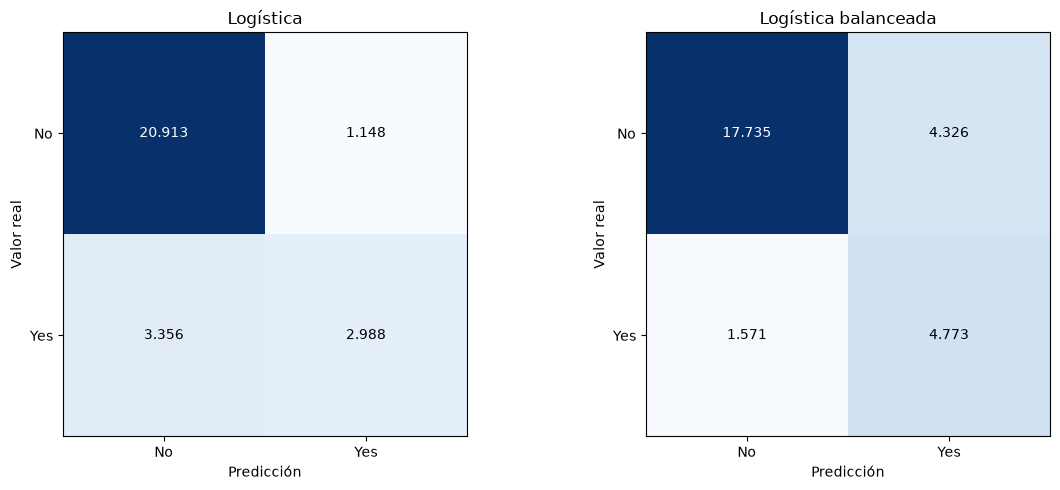

In [19]:
# Defino una función para graficar matrices de confusión y la aplico a cada modelo en prueba.
etiquetas_clases = ["No", "Yes"]

def graficar_matriz_confusion(ax, matriz, titulo):
    ax.imshow(matriz, cmap="Blues")
    for fila in range(2):
        for columna in range(2):
            ax.text(
                columna,
                fila,
                f"{matriz[fila, columna]:,}".replace(",", "."),
                ha="center",
                va="center",
                color="white" if matriz[fila, columna] > matriz.max() / 2 else "black",
            )
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(etiquetas_clases)
    ax.set_yticklabels(etiquetas_clases)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
    ax.set_title(titulo)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    matriz = confusion_matrix(y_test_bin, modelo.predict(X_test_prep))
    graficar_matriz_confusion(ax, matriz, nombre)
plt.tight_layout()
plt.show()

Con umbral 0,5, la regresión logística estándar tiene 3.356 falsos negativos y 1.148 falsos positivos. La versión balanceada reduce los falsos negativos a 1.571, pero sube los falsos positivos a 4.326.

Cuál de los dos errores es más grave depende del uso del pronóstico. Un falso negativo significa que llueve sin aviso, por ejemplo, alguien sale sin paraguas o no protege una cosecha o un evento al aire libre. Un falso positivo es una falsa alarma: se suspende o se prepara algo que no hacía falta. Para un pronóstico de uso general consideramos más costoso el falso negativo, así que priorizamos el recall de `Yes` sin dejar que la precision caiga demasiado. Esto lo tenemos en cuenta al elegir el umbral.


### Curva ROC y elección del umbral

Los modelos predicen Yes cuando la probabilidad estimada es mayor o igual a 0,5, pero ese valor es solo el umbral por defecto. La curva ROC muestra, para todos los umbrales posibles, la tasa de verdaderos positivos (recall de Yes) contra la tasa de falsos positivos.

El umbral es una decisión sobre el modelo, así que no lo elegimos mirando el conjunto de prueba. Separamos el último 20 % de las fechas de entrenamiento como validación, con el mismo criterio cronológico que el split principal, y entrenamos los dos modelos con el resto. Sobre validación calculamos la curva ROC y elegimos el umbral que maximiza la diferencia entre la tasa de verdaderos positivos y la de falsos positivos (índice de Youden). Ese umbral corresponde al punto de la curva más alejado de la diagonal.

In [20]:
# Separo el último tramo de entrenamiento como validación y entreno los modelos sin él.
fecha_corte_validacion = fechas_train.quantile(0.80)
mascara_subentrenamiento = fechas_train <= fecha_corte_validacion
X_subentrenamiento = X_train_prep.loc[mascara_subentrenamiento]
X_validacion = X_train_prep.loc[~mascara_subentrenamiento]
y_subentrenamiento = y_train_bin.loc[mascara_subentrenamiento]
y_validacion = y_train_bin.loc[~mascara_subentrenamiento]

modelos_validacion = {
    "Logística": LogisticRegression(max_iter=1000),
    "Logística balanceada": LogisticRegression(max_iter=1000, class_weight="balanced"),
}
for modelo in modelos_validacion.values():
    modelo.fit(X_subentrenamiento, y_subentrenamiento)

print("Subentrenamiento:", len(X_subentrenamiento), "| Validación:", len(X_validacion), "| Corte:", fecha_corte_validacion.date())

Subentrenamiento: 91027 | Validación: 22721 | Corte: 2014-07-17


Logística: umbral elegido = 0.184 (TPR = 0.790, FPR = 0.225); con 0,5: TPR = 0.451, FPR = 0.047
Logística balanceada: umbral elegido = 0.424 (TPR = 0.796, FPR = 0.228); con 0,5: TPR = 0.732, FPR = 0.176


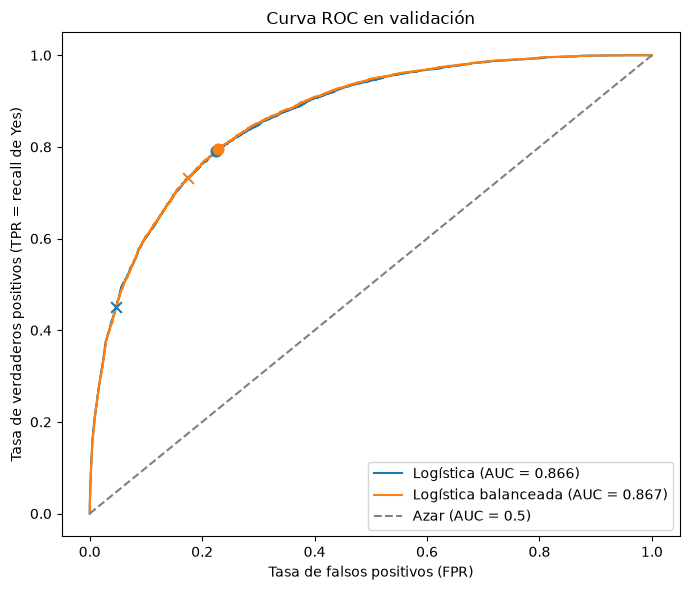

In [21]:
# Grafico la curva ROC de cada modelo en validación y marco el umbral elegido y el de 0,5.
umbrales_elegidos = {}
fig, ax = plt.subplots(figsize=(7, 6))

for nombre, modelo in modelos_validacion.items():
    y_prob_validacion = modelo.predict_proba(X_validacion)[:, 1]
    fpr, tpr, umbrales = roc_curve(y_validacion, y_prob_validacion)
    indice_mejor = (tpr - fpr).argmax()
    umbrales_elegidos[nombre] = umbrales[indice_mejor]

    prediccion_05 = y_prob_validacion >= 0.5
    tpr_05 = (prediccion_05 & (y_validacion == 1)).sum() / (y_validacion == 1).sum()
    fpr_05 = (prediccion_05 & (y_validacion == 0)).sum() / (y_validacion == 0).sum()

    linea, = ax.plot(fpr, tpr, label=f"{nombre} (AUC = {auc(fpr, tpr):.3f})")
    ax.scatter(fpr[indice_mejor], tpr[indice_mejor], color=linea.get_color(), s=60, zorder=3)
    ax.scatter(fpr_05, tpr_05, color=linea.get_color(), marker="x", s=60, zorder=3)
    print(f"{nombre}: umbral elegido = {umbrales[indice_mejor]:.3f} "
          f"(TPR = {tpr[indice_mejor]:.3f}, FPR = {fpr[indice_mejor]:.3f}); "
          f"con 0,5: TPR = {tpr_05:.3f}, FPR = {fpr_05:.3f}")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC = 0.5)")
ax.set_xlabel("Tasa de falsos positivos (FPR)")
ax.set_ylabel("Tasa de verdaderos positivos (TPR = recall de Yes)")
ax.set_title("Curva ROC en validación")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [22]:
# Comparo en prueba el umbral de 0,5 con el umbral elegido en validación.
filas_umbral = []
for nombre, modelo in modelos.items():
    y_prob_prueba = modelo.predict_proba(X_test_prep)[:, 1]
    for umbral in [0.5, umbrales_elegidos[nombre]]:
        y_pred = (y_prob_prueba >= umbral).astype(int)
        vn, fp, fn, vp = confusion_matrix(y_test_bin, y_pred).ravel()
        filas_umbral.append({
            "modelo": nombre,
            "umbral": round(umbral, 3),
            "precision (Yes)": precision_score(y_test_bin, y_pred),
            "recall (Yes)": recall_score(y_test_bin, y_pred),
            "F1 (Yes)": f1_score(y_test_bin, y_pred),
            "balanced accuracy": balanced_accuracy_score(y_test_bin, y_pred),
            "falsos negativos": fn,
            "falsos positivos": fp,
        })

display(pd.DataFrame(filas_umbral).set_index(["modelo", "umbral"]).round(3))

precision (Yes)  recall (Yes)  F1 (Yes)  \
modelo               umbral                                            
Logística            0.500             0.722         0.471     0.570   
                     0.184             0.480         0.806     0.602   
Logística balanceada 0.500             0.525         0.752     0.618   
                     0.424             0.473         0.816     0.599   

                             balanced accuracy  falsos negativos  \
modelo               umbral                                        
Logística            0.500               0.709              3356   
                     0.184               0.778              1230   
Logística balanceada 0.500               0.778              1571   
                     0.424               0.777              1170   

                             falsos positivos  
modelo               umbral                    
Logística            0.500               1148  
                     0.184               5531  
Logística balanceada 0.500               4326  
                     0.424               5756

Las curvas ROC de los dos modelos siguen mostrando comportamientos parecidos. En validación, con umbral 0,5 la logística estándar alcanza TPR = 0,451 y FPR = 0,047; el umbral elegido por Youden, 0,184, sube a TPR = 0,790 y FPR = 0,225. Para la versión balanceada, el umbral elegido es 0,424 (TPR = 0,796 y FPR = 0,228), frente a TPR = 0,732 y FPR = 0,176 con 0,5.

En prueba, aplicar el umbral elegido reduce los falsos negativos de la logística estándar de 3.356 a 1.230, y sube los falsos positivos de 1.148 a 5.531. En la versión balanceada, los falsos negativos bajan de 1.571 a 1.170 y los falsos positivos suben de 4.326 a 5.756. La balanced accuracy con umbral elegido queda en 0,778 y 0,777, respectivamente.

El índice de Youden no es la única forma de elegir el umbral. También se puede elegir el que maximiza el F1, fijar un recall mínimo de `Yes` y buscar el umbral con mayor precision que lo cumpla, o asignar un costo a cada tipo de error y minimizar el costo total. Elegimos Youden porque no requiere fijar costos arbitrarios y, en un dataset desbalanceado, favorece la detección de la clase minoritaria.


### Fitting

Para evaluar el ajuste comparamos entrenamiento y prueba. En la regresión logística estándar, la accuracy pasa de 0,845 a 0,841, el F1 de `Yes` de 0,596 a 0,570 y el AUC de 0,871 a 0,859. En la versión balanceada, la accuracy pasa de 0,791 a 0,792, el F1 de 0,626 a 0,618 y el AUC de 0,871 a 0,859. Las diferencias son pequeñas y no muestran una brecha marcada entre los períodos.

La balanced accuracy también se mantiene cercana entre entrenamiento y prueba (0,726 a 0,709 en el modelo estándar y 0,786 a 0,778 en el balanceado). Los datos de prueba son posteriores en el tiempo, así que parte de las diferencias puede reflejar cambio temporal. La regresión logística aprende una frontera lineal y su rendimiento sigue limitado para los días lluviosos; el ítem 4 comprueba si ajustar la regularización y el peso de clases cambia ese resultado.


## 3. Modelo base

El modelo base sirve para tener un piso: si un modelo más complejo no lo supera, no aporta nada. En este ítem usamos dos tipos de referencia.

Primero, dos variantes de `DummyClassifier`, que no aprenden relaciones entre las variables. `most_frequent` predice siempre `No`, la clase mayoritaria. `stratified` sortea `Yes` y `No` respetando sus proporciones; fijamos `random_state=42` para que el sorteo sea siempre igual. La primera muestra qué accuracy se obtiene sin detectar ninguna lluvia; la segunda, qué pasa con un clasificador aleatorio.

Segundo, una regla simple: si `RainToday` es `Yes`, predecimos `Yes`; si no, `No`. Es la señal más obvia y está disponible a las 23:59, así que no usa información del futuro. Si falta `RainToday`, la regla predice `No`; en todo el dataset eso pasa en 3.260 filas (2,24 %). No usamos `RainfallTomorrow` porque es la lluvia del día siguiente.

No usamos un árbol ni otro modelo más complejo como base: eso ya sería un candidato a optimizar, no una referencia. Para comparar bien, usamos el mismo split y las mismas filas de prueba del ítem 2. El Dummy ignora las variables, así que el preprocesamiento no le cambia el resultado; la regla usa `RainToday` crudo. Por eso en este ítem no hace falta un pipeline. El pipeline va a ser útil en el ítem 4, cuando hagamos validación cruzada.

El enunciado dice "repetir los pasos del ítem 3"; por la numeración, entendemos que se refiere a los pasos de evaluación del ítem 2. Repetimos métricas, matrices de confusión y curvas, adaptadas a modelos que no entrenan.


In [23]:
# Entreno los dos Dummy con los datos de entrenamiento
from sklearn.dummy import DummyClassifier

baselines = {
    "Dummy mayoritario": DummyClassifier(strategy="most_frequent"),
    "Dummy estratificado": DummyClassifier(strategy="stratified", random_state=42),
}
for nombre, modelo in baselines.items():
    # El Dummy ignora X, pero lo pasamos para mantener la interfaz de scikit-learn.
    modelo.fit(X_train_prep, y_train_bin)
    print(f"{nombre}: listo")


Dummy mayoritario: listo
Dummy estratificado: listo


In [24]:
# Calculo las métricas de los modelos base en entrenamiento y prueba
def calcular_metricas(y_real, y_pred, y_score):
    return {
        "accuracy": accuracy_score(y_real, y_pred),
        "precision (Yes)": precision_score(y_real, y_pred, zero_division=0),
        "recall (Yes)": recall_score(y_real, y_pred, zero_division=0),
        "F1 (Yes)": f1_score(y_real, y_pred, zero_division=0),
        "recall (No)": recall_score(y_real, y_pred, pos_label=0, zero_division=0),
        "AUC": roc_auc_score(y_real, y_score),
        "balanced accuracy": balanced_accuracy_score(y_real, y_pred),
        "MCC": matthews_corrcoef(y_real, y_pred),
        "average precision": average_precision_score(y_real, y_score),
    }

conjuntos_baseline = {
    "Entrenamiento": (X_train_prep, X_train, y_train_bin),
    "Prueba": (X_test_prep, X_test, y_test_bin),
}
filas_baseline = []
for nombre, modelo in baselines.items():
    for conjunto, (X_prep, _, y_real) in conjuntos_baseline.items():
        y_pred = modelo.predict(X_prep)
        y_score = modelo.predict_proba(X_prep)[:, 1]
        filas_baseline.append({
            "modelo": nombre,
            "conjunto": conjunto,
            **calcular_metricas(y_real, y_pred, y_score),
        })
for conjunto, (_, X_crudo, y_real) in conjuntos_baseline.items():
    # Si RainToday falta, la comparación da False y la regla predice No.
    y_pred = (X_crudo["RainToday"] == "Yes").astype(int).to_numpy()
    filas_baseline.append({
        "modelo": "Regla RainToday",
        "conjunto": conjunto,
        **calcular_metricas(y_real, y_pred, y_pred),
    })

metricas_baseline = pd.DataFrame(filas_baseline).set_index(["modelo", "conjunto"])
display(metricas_baseline.round(3))


accuracy  precision (Yes)  recall (Yes)  \
modelo              conjunto                                                 
Dummy mayoritario   Entrenamiento     0.776            0.000         0.000   
                    Prueba            0.777            0.000         0.000   
Dummy estratificado Entrenamiento     0.652            0.225         0.225   
                    Prueba            0.651            0.219         0.219   
Regla RainToday     Entrenamiento     0.762            0.468         0.462   
                    Prueba            0.753            0.447         0.441   

                                   F1 (Yes)  recall (No)    AUC  \
modelo              conjunto                                      
Dummy mayoritario   Entrenamiento     0.000        1.000  0.500   
                    Prueba            0.000        1.000  0.500   
Dummy estratificado Entrenamiento     0.225        0.776  0.500   
                    Prueba            0.219        0.776  0.497   
Regla RainToday     Entrenamiento     0.465        0.848  0.655   
                    Prueba            0.444        0.843  0.642   

                                   balanced accuracy    MCC  average precision  
modelo              conjunto                                                    
Dummy mayoritario   Entrenamiento              0.500  0.000              0.224  
                    Prueba                     0.500  0.000              0.223  
Dummy estratificado Entrenamiento              0.500  0.001              0.225  
                    Prueba                     0.497 -0.005              0.222  
Regla RainToday     Entrenamiento              0.655  0.312              0.337  
                    Prueba                     0.642  0.285              0.322

In [25]:
# Comparo en prueba los modelos base con las regresiones logísticas del ítem 2
comparacion_prueba = pd.concat([
    metricas_baseline.xs("Prueba", level="conjunto"),
    metricas.xs("Prueba", level="conjunto"),
])
display(comparacion_prueba.round(3))


,accuracy,precision (Yes),recall (Yes),F1 (Yes),recall (No),AUC,balanced accuracy,MCC,average precision
modelo,,,,,,,,,
Dummy mayoritario,0.777,0.000,0.000,0.000,1.000,0.500,0.500,0.000,0.223
Dummy estratificado,0.651,0.219,0.219,0.219,0.776,0.497,0.497,-0.005,0.222
Regla RainToday,0.753,0.447,0.441,0.444,0.843,0.642,0.642,0.285,0.322
Logística,0.841,0.722,0.471,0.570,0.948,0.859,0.709,0.495,0.675
Logística balanceada,0.792,0.525,0.752,0.618,0.804,0.859,0.778,0.497,0.673


En prueba, el Dummy mayoritario acierta el 77,7 % de las filas, pero no predice ningún `Yes`. Su recall, F1 y MCC dan 0, y la precision también da 0 porque no hay positivos predichos; usamos `zero_division=0` para que el cálculo no falle. Esa accuracy es la misma proporción de `No` del conjunto: no muestra ninguna capacidad de detectar lluvia. El Dummy estratificado baja a 0,651 y su AUC es 0,497: no distingue los días de lluvia de los secos.

La regla `RainToday` tiene menos accuracy (0,753), pero mejora las métricas de la clase `Yes`: precision 0,447, recall 0,441, F1 0,444, balanced accuracy 0,642, MCC 0,285 y average precision 0,322. Es una referencia más exigente que el Dummy, porque usa información real disponible al momento de la predicción.

La regresión logística estándar sigue arriba: accuracy 0,841, precision 0,722, recall 0,471, F1 0,570, balanced accuracy 0,709, MCC 0,495 y average precision 0,675. La versión balanceada baja la precision y sube el recall. Ambos modelos entrenados superan lo que consigue la regla de `RainToday`.

No optimizamos el umbral de los modelos base. El Dummy no da una probabilidad calibrada: sus puntajes son constantes o aleatorios. La regla ya tiene un corte fijo: `RainToday = Yes`. La comparación de umbrales queda para los modelos probabilísticos, como en el ítem 2.


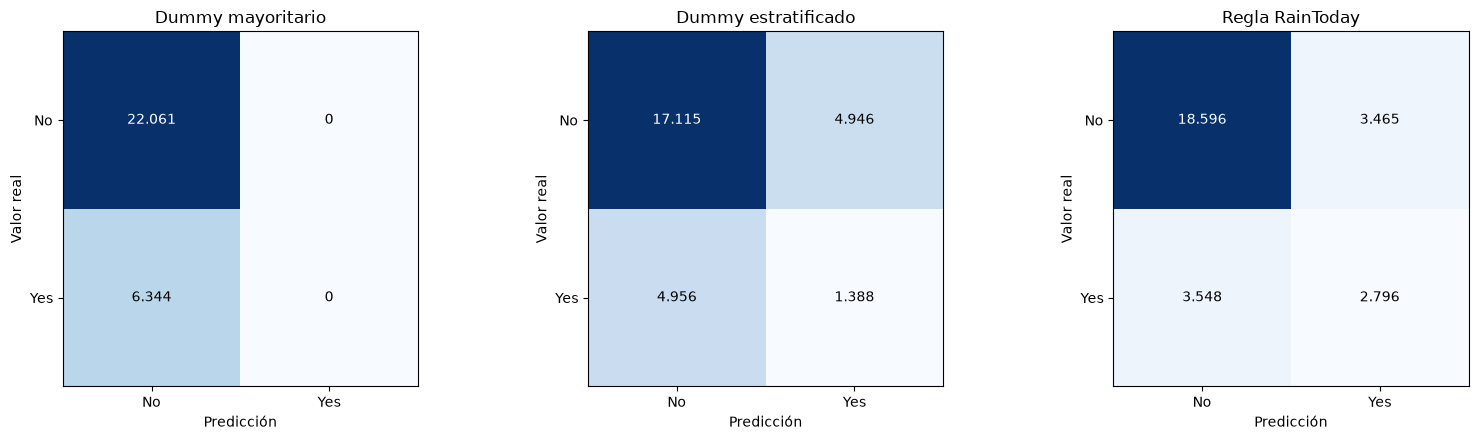

In [26]:
# Grafico las matrices de confusión de los tres modelos base en prueba
predicciones_baseline = {
    "Dummy mayoritario": baselines["Dummy mayoritario"].predict(X_test_prep),
    "Dummy estratificado": baselines["Dummy estratificado"].predict(X_test_prep),
    "Regla RainToday": (X_test["RainToday"] == "Yes").astype(int).to_numpy(),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (nombre, y_pred) in zip(axes, predicciones_baseline.items()):
    matriz = confusion_matrix(y_test_bin, y_pred)
    graficar_matriz_confusion(ax, matriz, nombre)
plt.tight_layout()
plt.show()


Las matrices permiten ver qué tipo de error comete cada modelo base. El Dummy mayoritario manda todo a `No`: 22.061 verdaderos negativos y 6.344 falsos negativos, sin falsos positivos ni verdaderos positivos. Acierta la clase mayoritaria, pero no detecta ninguna lluvia.

El Dummy estratificado reparte los errores: 17.115 verdaderos negativos, 4.946 falsos positivos, 4.956 falsos negativos y 1.388 verdaderos positivos. La regla `RainToday` queda más equilibrada: 18.596 verdaderos negativos, 3.465 falsos positivos, 3.548 falsos negativos y 2.796 verdaderos positivos. La regresión logística estándar tiene 1.148 falsos positivos y 3.356 falsos negativos; frente a ella, la regla genera 2.317 falsas alarmas más y deja pasar 192 días lluviosos más.

Un falso negativo es una lluvia sin aviso; un falso positivo, una falsa alarma. Para este problema nos importa más el falso negativo, pero tampoco queremos una precision tan baja que el pronóstico pierda utilidad.


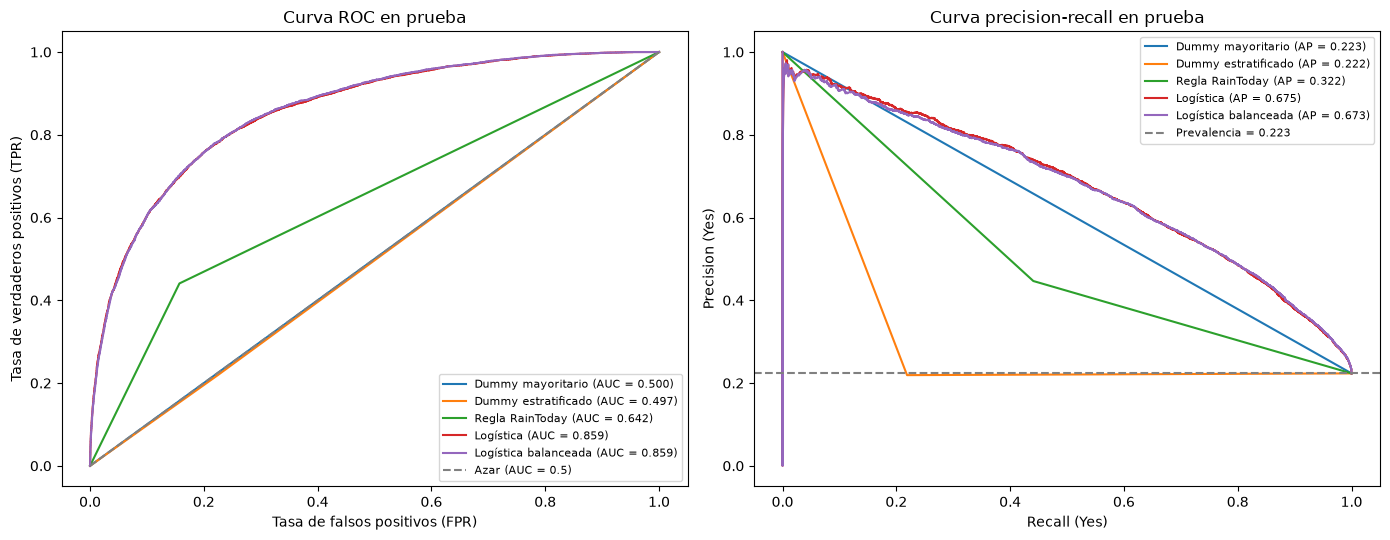

In [27]:
# Comparo las curvas ROC y precision-recall de los modelos base y de las regresiones logísticas en prueba
from sklearn.metrics import precision_recall_curve
puntajes_prueba = {
    "Dummy mayoritario": baselines["Dummy mayoritario"].predict_proba(X_test_prep)[:, 1],
    "Dummy estratificado": baselines["Dummy estratificado"].predict_proba(X_test_prep)[:, 1],
    "Regla RainToday": (X_test["RainToday"] == "Yes").astype(int).to_numpy(),
}
for nombre, modelo in modelos.items():
    puntajes_prueba[nombre] = modelo.predict_proba(X_test_prep)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for nombre, puntaje in puntajes_prueba.items():
    fpr, tpr, _ = roc_curve(y_test_bin, puntaje)
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y_test_bin, puntaje):.3f})")
    precision, recall, _ = precision_recall_curve(y_test_bin, puntaje)
    axes[1].plot(recall, precision, label=f"{nombre} (AP = {average_precision_score(y_test_bin, puntaje):.3f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC = 0.5)")
axes[0].set_xlabel("Tasa de falsos positivos (FPR)")
axes[0].set_ylabel("Tasa de verdaderos positivos (TPR)")
axes[0].set_title("Curva ROC en prueba")
axes[0].legend(loc="lower right", fontsize=8)

prevalencia = y_test_bin.mean()
axes[1].axhline(prevalencia, linestyle="--", color="gray", label=f"Prevalencia = {prevalencia:.3f}")
axes[1].set_xlabel("Recall (Yes)")
axes[1].set_ylabel("Precision (Yes)")
axes[1].set_title("Curva precision-recall en prueba")
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()


La curva ROC muestra qué tan bien el modelo separa los días con lluvia de los que no, para distintos umbrales. En los modelos base no aporta mucho, porque no dan una probabilidad útil. El Dummy mayoritario da siempre la misma probabilidad, así que su AUC queda en 0,5, igual que el azar. El Dummy estratificado también queda cerca de 0,5 porque sortea las clases. La regla `RainToday` solo devuelve `Yes` o `No`, no una probabilidad; por eso su ROC es un solo punto y su AUC da 0,642, el mismo valor que la balanced accuracy.

Para comparar estos modelos, la curva precision-recall es más útil porque `Yes` es la clase minoritaria. El average precision resume esa curva: cuanto más alto, mejor es el modelo para encontrar días de lluvia sin llenarse de falsos positivos. El Dummy mayoritario da 0,223, que es la prevalencia de `Yes`; el Dummy estratificado, ≈0,222; la regla, 0,322; y la regresión logística, 0,675.

Las líneas rectas de los modelos base solo unen pocos puntos: no tienen probabilidades intermedias. Por eso no hay que mirar el área dibujada, sino el average precision, que se calcula con los cortes reales.

Estas curvas son de prueba y las usamos solo para comparar. El umbral del ítem 2 se eligió en validación, no acá.


### ¿Hay fitting en un modelo base?

No en el sentido habitual. El Dummy no aprende parámetros y la regla es fija; no hay un entrenamiento que pueda memorizar los datos. Por eso no tiene sentido hablar de sobreajuste o subajuste como en la regresión logística. Lo que sí podemos mirar es que el comportamiento sea estable entre entrenamiento y prueba. En el Dummy mayoritario, la accuracy es 0,776 en entrenamiento y 0,777 en prueba; en la regla, 0,762 y 0,753. La diferencia es chica y no indica sobreajuste. Puede deberse a la proporción de clases en cada período, ya que prueba corresponde a fechas posteriores.

El análisis de fitting que importa sigue siendo el de la regresión logística del ítem 2: allí las métricas de train y prueba están cerca y no hay señales de sobreajuste. El modelo base no reemplaza ese análisis: sirve solo para marcar el piso.


### Conclusión del ítem 3

El Dummy mayoritario confirma que la accuracy sola es engañosa: 77,7 % de aciertos y 0 % de recall de `Yes`. La regla `RainToday` es un modelo base más exigente: con menos accuracy (0,753), mejora el MCC (0,285), la balanced accuracy (0,642) y el average precision (0,322). Aun así, queda lejos de la regresión logística estándar, que alcanza MCC 0,495, balanced accuracy 0,709 y average precision 0,675. La versión balanceada sube la balanced accuracy a 0,778, pero baja la precision.

Eso muestra que la regresión logística aprende algo más que la señal más obvia de `RainToday`. Los modelos base no son candidatos para el modelo final: son referencias. El ítem 3 no necesita pipeline ni optimización de umbral; esas decisiones aparecen en los próximos ítems.


## 4. Optimización de hiperparámetros

En este ítem buscamos mejorar la regresión logística del ítem 2 sin usar el conjunto de prueba. El pipeline incluye `RobustScaler` e imputación por mediana para predictores numéricos originales y derivados, además de imputación categórica y one-hot solo para `RainToday`. La transformación cíclica del viento, las coordenadas y la estacionalidad anual se construyen de forma determinista antes del split; el escalador y los imputadores se ajustan dentro de cada partición de entrenamiento.

Como los datos son temporales, no usamos un `KFold` aleatorio: ordenamos por fecha y armamos 4 cortes con `TimeSeriesSplit` sobre las fechas únicas. Cada corte entrena con el pasado y valida con el tramo siguiente. Después llevamos esos cortes a las filas, así una misma fecha no queda en entrenamiento y validación. Todos los candidatos usan los mismos cortes y el conjunto de prueba queda intacto hasta la evaluación final.

Optimizamos `C` (en scikit-learn es el inverso de lambda: cuanto más chico, más regulariza) y `class_weight` (`None` o `"balanced"`). No tocamos el solver ni la penalización: los modelos del ítem 2 convergen con `max_iter=1000`, y cambiarlos agregaría costo sin una hipótesis clara. Usamos `GridSearchCV` porque tenemos dos hiperparámetros y una grilla chica: seis valores de `C` (0,01 a 1000) por dos opciones de `class_weight`, 12 combinaciones. La cátedra recomienda grid para uno o dos hiperparámetros; random search queda para espacios más grandes. Probamos `C` en potencias de 10 para cubrir desde mucha hasta casi ninguna regularización. La métrica de selección es average precision, la misma que usamos para comparar modelos con clases desbalanceadas. También guardamos el score de entrenamiento para revisar sobreajuste.


In [28]:
# Armo el pipeline y busco hiperparámetros con una grilla y validación temporal.
import warnings

import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing import OneHotEncoder

# El CSV no está ordenado por fecha; ordeno solo entrenamiento para que TimeSeriesSplit respete el tiempo.
fechas_train_ordenadas = fechas_train.sort_values()
X_train_ordenado = X_train.loc[fechas_train_ordenadas.index]
y_train_ordenado = y_train_bin.loc[fechas_train_ordenadas.index]

# Los cortes se arman con fechas únicas y después se traducen a filas.
fechas_unicas = np.sort(fechas_train_ordenadas.unique())
folds_temporales = []
for fechas_entrenamiento_idx, fechas_validacion_idx in TimeSeriesSplit(n_splits=4).split(fechas_unicas):
    fechas_entrenamiento = fechas_unicas[fechas_entrenamiento_idx]
    fechas_validacion = fechas_unicas[fechas_validacion_idx]
    filas_entrenamiento = np.flatnonzero(
        fechas_train_ordenadas.isin(fechas_entrenamiento).to_numpy()
    )
    filas_validacion = np.flatnonzero(
        fechas_train_ordenadas.isin(fechas_validacion).to_numpy()
    )
    folds_temporales.append((filas_entrenamiento, filas_validacion))

# Mantengo el orden del ítem 2: primero escalo y después imputo con la mediana.
pipeline_numerico = Pipeline(steps=[
    ("escalador", RobustScaler()),
    ("imputador", SimpleImputer(strategy="median")),
])
pipeline_categorico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="constant", fill_value="Faltante")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore")),
])
preprocesador = ColumnTransformer(transformers=[
    ("numericas", pipeline_numerico, columnas_numericas_modelo),
    ("categoricas", pipeline_categorico, columnas_categoricas_modelo),
])

pipeline_logistica = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("modelo", LogisticRegression(max_iter=1000)),
])

espacio_busqueda = {
    "modelo__C": [0.01, 0.1, 1, 10, 100, 1000],
    "modelo__class_weight": [None, "balanced"],
}

busqueda = GridSearchCV(
    estimator=pipeline_logistica,
    param_grid=espacio_busqueda,
    scoring="average_precision",
    cv=folds_temporales,
    n_jobs=1,
    return_train_score=True,
    refit=True,
)

# En algunos folds RainToday tiene categorías no vistas; ignore las codifica como cero.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Found unknown categories")
    busqueda.fit(X_train_ordenado, y_train_ordenado)

print(f"Mejor AP en validación cruzada: {busqueda.best_score_:.4f}")
print(f"Mejor C: {busqueda.best_params_['modelo__C']:.4f}")
print(f"class_weight: {busqueda.best_params_['modelo__class_weight']}")


Mejor AP en validación cruzada: 0.6927
Mejor C: 0.1000
class_weight: None


### Resultados de la validación cruzada

La tabla muestra las 10 mejores combinaciones. `AP validación` es el average precision promedio en los 4 cortes; `AP entrenamiento` es el promedio en los tramos de entrenamiento de cada corte. Los cortes se definen por fecha, no por fila. La grilla de `C` usa potencias de 10. En total se ajustaron 48 modelos: 12 combinaciones por 4 folds.


In [29]:
# Muestro las mejores combinaciones de la búsqueda.
resultados_cv = pd.DataFrame(busqueda.cv_results_)
tabla_cv = resultados_cv.sort_values("rank_test_score")[[
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "param_modelo__C",
    "param_modelo__class_weight",
]].head(10).reset_index(drop=True).copy()

tabla_cv["param_modelo__C"] = tabla_cv["param_modelo__C"].astype(float).round(4)
tabla_cv["param_modelo__class_weight"] = tabla_cv["param_modelo__class_weight"].fillna("None")
tabla_cv = tabla_cv.rename(columns={
    "rank_test_score": "posición",
    "mean_test_score": "AP validación",
    "std_test_score": "desvío validación",
    "mean_train_score": "AP entrenamiento",
    "param_modelo__C": "C",
    "param_modelo__class_weight": "class_weight",
})
display(tabla_cv.round(4))


,posición,AP validación,desvío validación,AP entrenamiento,C,class_weight
0,1,0.6927,0.0172,0.7048,0.1,None
1,2,0.6927,0.0173,0.7053,1.0,None
2,3,0.6923,0.0172,0.7053,10.0,None
3,4,0.6923,0.0172,0.7053,100.0,None
4,5,0.6922,0.0171,0.7053,1000.0,None
5,6,0.6909,0.0172,0.7019,0.1,balanced
6,7,0.6907,0.0174,0.7023,1.0,balanced
7,8,0.6902,0.0172,0.7022,10.0,balanced
8,9,0.6901,0.0172,0.7022,1000.0,balanced
9,10,0.6900,0.0171,0.7021,100.0,balanced


### Evaluación del mejor modelo

Reentrenamos el mejor pipeline con todo el entrenamiento y lo evaluamos una sola vez en prueba. Para comparar, incluimos las métricas de los dos modelos del ítem 2. El umbral sigue siendo 0,5: en este ítem optimizamos hiperparámetros, no el punto de corte.


In [30]:
# Evalúo el mejor pipeline en entrenamiento y prueba.
mejor_modelo = busqueda.best_estimator_

filas_item4 = []
for conjunto, (X_conjunto, y_conjunto) in {
    "Entrenamiento": (X_train_ordenado, y_train_ordenado),
    "Prueba": (X_test, y_test_bin),
}.items():
    y_pred = mejor_modelo.predict(X_conjunto)
    y_score = mejor_modelo.predict_proba(X_conjunto)[:, 1]
    filas_item4.append({
        "modelo": "Logística optimizada",
        "conjunto": conjunto,
        **calcular_metricas(y_conjunto, y_pred, y_score),
    })

metricas_item4 = pd.DataFrame(filas_item4).set_index(["modelo", "conjunto"])
display(metricas_item4.round(3))

comparacion_item4 = pd.concat([metricas, metricas_item4])
display(comparacion_item4.xs("Prueba", level="conjunto").round(3))


accuracy  precision (Yes)  recall (Yes)  \
modelo               conjunto                                                 
Logística optimizada Entrenamiento     0.845            0.720         0.508   
                     Prueba            0.841            0.722         0.470   

                                    F1 (Yes)  recall (No)    AUC  \
modelo               conjunto                                      
Logística optimizada Entrenamiento     0.596        0.943  0.871   
                     Prueba            0.569        0.948  0.859   

                                    balanced accuracy    MCC  \
modelo               conjunto                                  
Logística optimizada Entrenamiento              0.725  0.515   
                     Prueba                     0.709  0.494   

                                    average precision  
modelo               conjunto                          
Logística optimizada Entrenamiento              0.698  
                     Prueba                     0.675

,accuracy,precision (Yes),recall (Yes),F1 (Yes),recall (No),AUC,balanced accuracy,MCC,average precision
modelo,,,,,,,,,
Logística,0.841,0.722,0.471,0.570,0.948,0.859,0.709,0.495,0.675
Logística balanceada,0.792,0.525,0.752,0.618,0.804,0.859,0.778,0.497,0.673
Logística optimizada,0.841,0.722,0.470,0.569,0.948,0.859,0.709,0.494,0.675


### Conclusión del ítem 4

La grilla eligió `C=0,1` y `class_weight=None`. Con cuatro decimales, su AP de validación (0,6927) coincide con el de `C=1` (0,6927); los desvíos entre folds son 0,0172 y 0,0173. `C=10`, `100` y `1000` quedan apenas por debajo, y la mejor combinación balanceada alcanza 0,6909. No hay una mejora relevante frente a `C=1`: el AP de entrenamiento fue 0,7048, el promedio de validación cruzada 0,6927 y el AP de prueba 0,675.

En prueba, el pipeline optimizado alcanza accuracy 0,841, precision 0,722, recall 0,470, F1 0,569, MCC 0,494, AUC 0,859 y AP 0,675, casi igual a la logística estándar del ítem 2. `class_weight="balanced"` sube el recall pero baja la precision y no mejora el AP. El umbral sigue teniendo más efecto sobre ese intercambio que el ajuste de `C`.

El pipeline se ajusta dentro de cada fold, así que escalado, imputación y one-hot no usan información de validación. El conjunto de prueba se usó una sola vez, al final. El mejor pipeline queda en `mejor_modelo` para el ítem de explicabilidad.


## 5. Explicabilidad de los modelos

Para este ítem explicamos el mejor pipeline del ítem 4, sin volver a entrenarlo. El explicador usa una muestra de entrenamiento como referencia y explica observaciones de prueba; los dos ejemplos locales también salen de prueba. Para las figuras globales usamos una muestra reproducible de hasta 2.000 filas.

SHAP describe el componente lineal de la regresión logística en log-odds: un valor positivo empuja la predicción hacia `RainTomorrow = Yes` y uno negativo hacia `No`. Agrupamos los pares seno/coseno de fecha, las coordenadas y las tres componentes de cada viento para mostrar aportes por variable original. `RainToday` conserva solo sus dummies. SHAP describe el modelo y no una relación causal.


C:\Users\Tomas\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Version de SHAP: 0.54.1
Background de entrenamiento: (512, 31)
Observaciones de prueba explicadas globalmente: 2000


,fecha de observación,Location,clase real,clase predicha,probabilidad de lluvia
caso,,,,,
"Lluvia, mayor confianza",2016-06-05,Sydney,Yes,Yes,0.998
"Sin lluvia, mayor confianza",2016-04-24,Woomera,No,No,0.001


Cinco variables con mayor importancia media absoluta:


,SHAP medio absoluto (log-odds)
Humidity3pm,0.868320
Pressure3pm,0.786971
Pressure9am,0.505003
WindGustSpeed,0.483365
Date,0.232995


Cinco variables con menor importancia media absoluta:


,SHAP medio absoluto (log-odds)
Cloud9am,0.003522
Evaporation,0.023247
Rainfall,0.043788
WindDir9am,0.062336
WindGustDir,0.065398


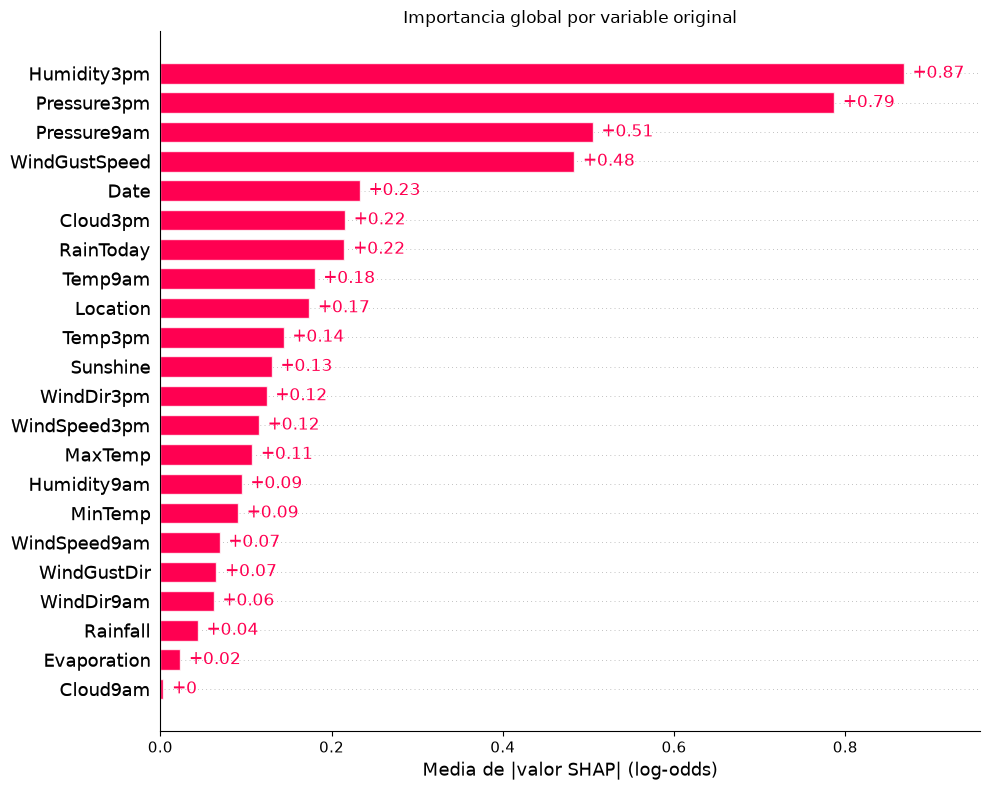

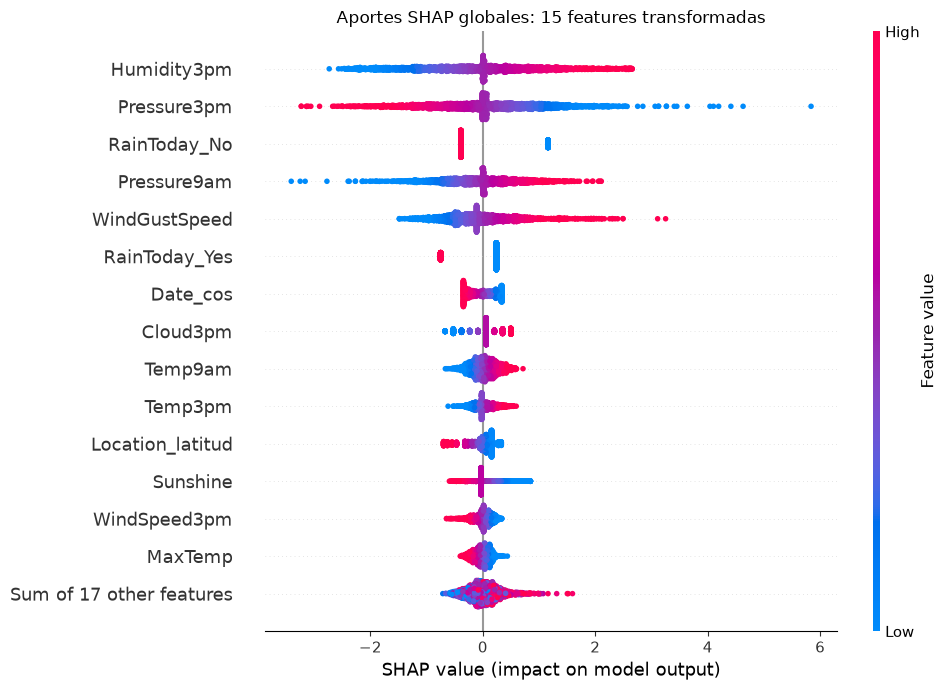

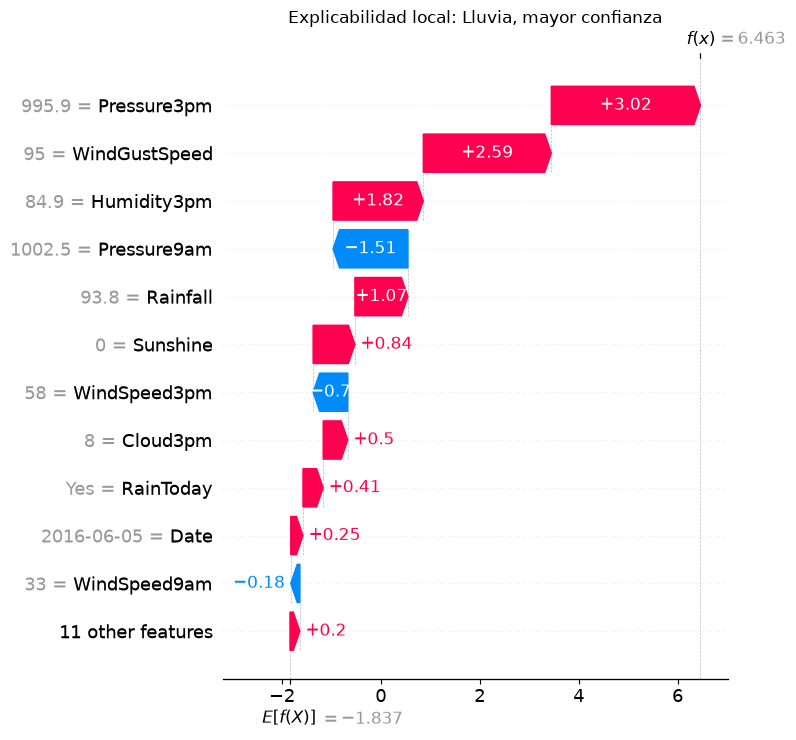

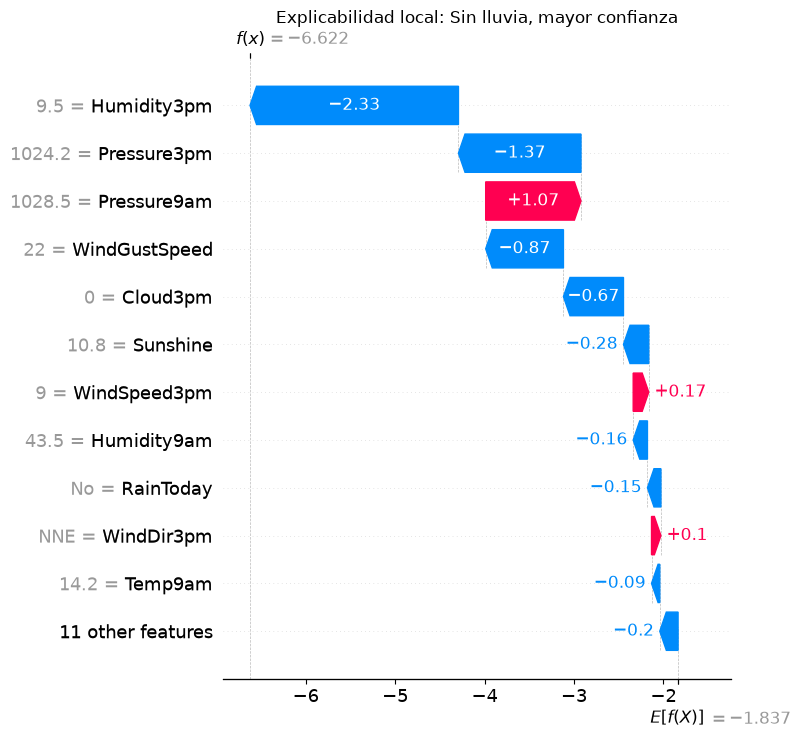

Error maximo de reconstruccion SHAP de decision_function: 8.88e-16


### Lectura de las explicaciones

En la muestra de prueba, las variables con mayor importancia media absoluta agrupada son: Humidity3pm (0.868), Pressure3pm (0.787), Pressure9am (0.505), WindGustSpeed (0.483), Date (0.233). Las de menor importancia son: Cloud9am (0.004), Evaporation (0.023), Rainfall (0.044), WindDir9am (0.062), WindGustDir (0.065). Esta medida promedia la magnitud de los aportes por observación; no indica si una variable aumenta o reduce la lluvia.

En el caso local con lluvia, los aportes que más empujan hacia Yes son Pressure3pm (+3.017), WindGustSpeed (+2.588), Humidity3pm (+1.825); los que más empujan hacia No son Pressure9am (-1.514), WindSpeed3pm (-0.700), WindSpeed9am (-0.184). En el caso local sin lluvia, los aportes que más empujan hacia Yes son Pressure9am (+1.065), WindSpeed3pm (+0.174), WindDir3pm (+0.105); los que más empujan hacia No son Humidity3pm (-2.330), Pressure3pm (-1.370), WindGustSpeed (-0.869). Los valores positivos y negativos se interpretan en log-odds y corresponden a los dos waterfalls.

El beeswarm complementa la importancia agrupada: cada punto representa una observación de prueba, su posición muestra la dirección y magnitud del aporte, y el color indica el valor de la feature transformada. La explicación describe el comportamiento de esta regresión logística; no demuestra causalidad.

In [31]:
# Explico el componente lineal del mejor pipeline usando entrenamiento como background.
import numpy as np
import shap
from IPython.display import Markdown, display

preprocesador_shap = mejor_modelo.named_steps["preprocesamiento"]
modelo_shap = mejor_modelo.named_steps["modelo"]
nombres_features_shap = preprocesador_shap.get_feature_names_out()
nombres_features_visibles = [
    nombre.split("__", 1)[-1] if "__" in nombre else nombre
    for nombre in nombres_features_shap
]

columnas_predictoras_explicables = [
    *columnas_predictoras_numericas,
    "Date",
    "Location",
    *columnas_direcciones_viento,
    *columnas_categoricas_modelo,
]

def matriz_densa_shap(matriz):
    # ColumnTransformer puede devolver una matriz dispersa por las columnas one-hot.
    return matriz.toarray() if hasattr(matriz, "toarray") else np.asarray(matriz)

n_background_shap = min(512, len(X_train_ordenado))
X_background_shap = X_train_ordenado.sample(n=n_background_shap, random_state=42)
X_background_transformado = matriz_densa_shap(
    preprocesador_shap.transform(X_background_shap)
)

n_global_shap = min(2000, len(X_test))
X_test_global_shap = X_test.sample(n=n_global_shap, random_state=42)
X_test_global_transformado = matriz_densa_shap(
    preprocesador_shap.transform(X_test_global_shap)
)

mascara_shap = shap.maskers.Independent(
    X_background_transformado,
    max_samples=n_background_shap,
)
explicador_shap = shap.Explainer(
    modelo_shap,
    mascara_shap,
    feature_names=nombres_features_visibles,
    algorithm="linear",
    seed=42,
)
explicaciones_globales = explicador_shap(X_test_global_transformado)

print("Version de SHAP:", shap.__version__)
print("Background de entrenamiento:", X_background_transformado.shape)
print("Observaciones de prueba explicadas globalmente:", X_test_global_transformado.shape[0])

# Selecciono un ejemplo lluvioso y uno seco, ambos correctamente clasificados y de alta confianza.
probabilidades_yes_test = mejor_modelo.predict_proba(X_test)[:, 1]
predicciones_test_shap = mejor_modelo.predict(X_test)
clases_reales_test = y_test_bin.to_numpy()

posiciones_yes_correctos = np.flatnonzero(
    (clases_reales_test == 1) & (predicciones_test_shap == 1)
)
posiciones_no_correctos = np.flatnonzero(
    (clases_reales_test == 0) & (predicciones_test_shap == 0)
)
if len(posiciones_yes_correctos) == 0 or len(posiciones_no_correctos) == 0:
    raise ValueError("No se encontraron ejemplos correctamente clasificados de ambas clases.")

pos_yes = posiciones_yes_correctos[
    np.argmax(probabilidades_yes_test[posiciones_yes_correctos])
]
pos_no = posiciones_no_correctos[
    np.argmin(probabilidades_yes_test[posiciones_no_correctos])
]
indices_locales_shap = [X_test.index[pos_yes], X_test.index[pos_no]]
X_test_local_shap = X_test.loc[indices_locales_shap]
X_test_local_transformado = matriz_densa_shap(
    preprocesador_shap.transform(X_test_local_shap)
)
explicaciones_locales = explicador_shap(X_test_local_transformado)

resumen_casos_locales = []
for nombre_caso, posicion, indice in [
    ("Lluvia, mayor confianza", pos_yes, indices_locales_shap[0]),
    ("Sin lluvia, mayor confianza", pos_no, indices_locales_shap[1]),
]:
    resumen_casos_locales.append({
        "caso": nombre_caso,
        "fecha de observación": fechas_test.loc[indice].date(),
        "Location": df.loc[indice, "Location"],
        "clase real": "Yes" if clases_reales_test[posicion] == 1 else "No",
        "clase predicha": "Yes" if predicciones_test_shap[posicion] == 1 else "No",
        "probabilidad de lluvia": probabilidades_yes_test[posicion],
    })
display(pd.DataFrame(resumen_casos_locales).set_index("caso").round({
    "probabilidad de lluvia": 3,
}))

# Agrupo los componentes derivados en las variables originales, preservando la suma SHAP.
def variable_original_shap(nombre_feature):
    nombre = nombre_feature.split("__", 1)[-1] if "__" in nombre_feature else nombre_feature
    if nombre in columnas_predictoras_numericas:
        return nombre
    if nombre in columnas_coordenadas:
        return "Location"
    if nombre in columnas_fecha_ciclica:
        return "Date"
    for variable in columnas_direcciones_viento:
        if nombre.startswith(variable + "_"):
            return variable
    for variable in columnas_categoricas_modelo:
        if nombre.startswith(variable + "_"):
            return variable
    raise ValueError(f"No se pudo asociar la feature transformada {nombre_feature!r}.")

posiciones_predictoras = {
    variable: posicion
    for posicion, variable in enumerate(columnas_predictoras_explicables)
}
variables_por_feature_shap = [
    variable_original_shap(nombre)
    for nombre in nombres_features_shap
]

def agrupar_aportes_por_predictor(valores):
    agrupados = np.zeros((valores.shape[0], len(columnas_predictoras_explicables)))
    for posicion_feature, variable in enumerate(variables_por_feature_shap):
        agrupados[:, posiciones_predictoras[variable]] += valores[:, posicion_feature]
    return agrupados

valores_globales_agrupados = agrupar_aportes_por_predictor(
    explicaciones_globales.values
)
explicaciones_globales_por_variable = shap.Explanation(
    values=valores_globales_agrupados,
    base_values=explicaciones_globales.base_values,
    feature_names=columnas_predictoras_explicables,
)

# Muestro la importancia media absoluta agrupada en las variables originales.
importancia_shap = pd.Series(
    np.abs(valores_globales_agrupados).mean(axis=0),
    index=columnas_predictoras_explicables,
    name="SHAP medio absoluto (log-odds)",
).sort_values(ascending=False)
print("Cinco variables con mayor importancia media absoluta:")
display(importancia_shap.head(5).to_frame())
print("Cinco variables con menor importancia media absoluta:")
display(importancia_shap.tail(5).sort_values().to_frame())

ax_importancia_shap = shap.plots.bar(
    explicaciones_globales_por_variable,
    max_display=len(columnas_predictoras_explicables),
    show=False,
)
ax_importancia_shap.figure.set_size_inches(10, 8)
ax_importancia_shap.set_title("Importancia global por variable original")
ax_importancia_shap.set_xlabel("Media de |valor SHAP| (log-odds)")
plt.tight_layout()
plt.show()

# El beeswarm conserva las componentes transformadas para mostrar el detalle de cada aporte.
ax_beeswarm_shap = shap.plots.beeswarm(
    explicaciones_globales,
    max_display=15,
    show=False,
    plot_size=(10, 7),
)
ax_beeswarm_shap.set_title("Aportes SHAP globales: 15 features transformadas")
plt.tight_layout()
plt.show()

# Para los waterfalls muestro valores de las variables originales junto con los aportes agrupados.
datos_locales_visibles = pd.DataFrame(index=X_test_local_shap.index)
for columna in columnas_predictoras_numericas:
    datos_locales_visibles[columna] = X_test_local_shap[columna].astype(object)
for columna in columnas_direcciones_viento:
    datos_locales_visibles[columna] = df.loc[X_test_local_shap.index, columna].astype(object)
datos_locales_visibles["Date"] = fechas_test.loc[X_test_local_shap.index].dt.strftime("%Y-%m-%d").astype(object)
datos_locales_visibles["Location"] = df.loc[X_test_local_shap.index, "Location"].astype(object)
datos_locales_visibles["RainToday"] = X_test_local_shap["RainToday"].astype(object)
for columna in columnas_predictoras_numericas:
    datos_locales_visibles[columna] = datos_locales_visibles[columna].where(
        pd.notna(datos_locales_visibles[columna]),
        "Faltante (imputado)",
    )
for columna in columnas_direcciones_viento + columnas_categoricas_modelo:
    datos_locales_visibles[columna] = datos_locales_visibles[columna].where(
        pd.notna(datos_locales_visibles[columna]),
        "Faltante",
    )
datos_locales_visibles = datos_locales_visibles[columnas_predictoras_explicables]

valores_locales_agrupados = agrupar_aportes_por_predictor(
    explicaciones_locales.values
)
explicaciones_locales_por_variable = shap.Explanation(
    values=valores_locales_agrupados,
    base_values=explicaciones_locales.base_values,
    data=datos_locales_visibles.to_numpy(dtype=object),
    feature_names=columnas_predictoras_explicables,
)

for posicion, nombre_caso in enumerate([
    "Lluvia, mayor confianza",
    "Sin lluvia, mayor confianza",
]):
    ax_local = shap.plots.waterfall(
        explicaciones_locales_por_variable[posicion],
        max_display=12,
        show=False,
    )
    ax_local.set_title(f"Explicabilidad local: {nombre_caso}")
    plt.tight_layout()
    plt.show()

salidas_modelo_locales = modelo_shap.decision_function(X_test_local_transformado)
error_aditivo_shap = np.max(np.abs(
    explicaciones_locales.base_values
    + explicaciones_locales.values.sum(axis=1)
    - salidas_modelo_locales
))
print(f"Error maximo de reconstruccion SHAP de decision_function: {error_aditivo_shap:.2e}")

def aportes_direccionales_shap(fila_aportes, positivos=True, cantidad=3):
    posiciones = [
        i for i, valor in enumerate(fila_aportes)
        if (valor > 0 if positivos else valor < 0)
    ]
    posiciones.sort(key=lambda i: fila_aportes[i], reverse=positivos)
    return ", ".join(
        f"{columnas_predictoras_explicables[i]} ({fila_aportes[i]:+.3f})"
        for i in posiciones[:cantidad]
    ) or "sin aportes en esta direccion"

top_variables_texto = ", ".join(
    f"{variable} ({valor:.3f})"
    for variable, valor in importancia_shap.head(5).items()
)
variables_menor_importancia_texto = ", ".join(
    f"{variable} ({valor:.3f})"
    for variable, valor in importancia_shap.tail(5).sort_values().items()
)
aporte_yes_positivo = aportes_direccionales_shap(valores_locales_agrupados[0], positivos=True)
aporte_yes_negativo = aportes_direccionales_shap(valores_locales_agrupados[0], positivos=False)
aporte_no_positivo = aportes_direccionales_shap(valores_locales_agrupados[1], positivos=True)
aporte_no_negativo = aportes_direccionales_shap(valores_locales_agrupados[1], positivos=False)

texto_observaciones_shap = (
    "### Lectura de las explicaciones\n\n"
    f"En la muestra de prueba, las variables con mayor importancia media absoluta agrupada son: {top_variables_texto}. "
    f"Las de menor importancia son: {variables_menor_importancia_texto}. "
    "Esta medida promedia la magnitud de los aportes por observación; no indica si una variable aumenta o reduce la lluvia.\n\n"
    f"En el caso local con lluvia, los aportes que más empujan hacia Yes son {aporte_yes_positivo}; "
    f"los que más empujan hacia No son {aporte_yes_negativo}. "
    f"En el caso local sin lluvia, los aportes que más empujan hacia Yes son {aporte_no_positivo}; "
    f"los que más empujan hacia No son {aporte_no_negativo}. "
    "Los valores positivos y negativos se interpretan en log-odds y corresponden a los dos waterfalls.\n\n"
    "El beeswarm complementa la importancia agrupada: cada punto representa una observación de prueba, "
    "su posición muestra la dirección y magnitud del aporte, y el color indica el valor de la feature transformada. "
    "La explicación describe el comportamiento de esta regresión logística; no demuestra causalidad."
)
display(Markdown(texto_observaciones_shap))
